# [GSE154992](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE154992)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-03-09
> - Modified: 2024-03-09

# 1. Experimental Design

> Combined analysis of ribo-seq and rna-seq reveals that Mettl3 regulates embryonic cerebral cortex development in mice by controlling the proliferation and differentiation of neural progenitor cells.
> - Du, K., Zhang, Z., Zeng, Z. et al. Distinct roles of Fto and Mettl3 in controlling development of the cerebral cortex through transcriptional and translational regulations. Cell Death Dis 12, 700 (2021). https://doi.org/10.1038/s41419-021-03992-2.
> - ribo(A) RNA-seq: NEBNext® UltraTM RNA Library Prep Kit from Illumina®
> - Ribo-seq: Treated with unspecific endoribonuclease RNase I
> - Illumina Novaseq, PE150
> - mm10

| Sample | Organism | Tissue | Genotype | Treatment | Fraction | Replicate |
| - | - | - | - | - | - | - |
| WT Ctrl mRNA | Mus musculus | Cerebral cortex | Wild Type | Control | Total RNA | rep1~3 |
| WT Ctrl Ribo | Mus musculus | Cerebral cortex | Wild Type | Control | Ribosome RNA | rep1~3 |
| Mettl3 cKO mRNA | Mus musculus | Cerebral cortex | Mettl3 flox/flox | Emx1-cre | Total RNA | rep1~3 |
| Mettl3 cKO Ribo | Mus musculus | Cerebral cortex | Mettl3 flox/flox | Emx1-cre | Ribosome RNA | rep1~3 |
| Fto cKO mRNA | Mus musculus | Cerebral cortex | Fto flox/flox | Emx1-cre | Total RNA | rep1~3 |
| Fto cKO Ribo | Mus musculus | Cerebral cortex | Fto flox/flox | Emx1-cre | Ribosome RNA | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/riboseq_Mm_Cortex_Mettl3_GSE154992"

In [3]:
raw_counts_ribo <- file.path(
    data_dir, "02_output_riboseq", "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts_ribo) <- colnames(raw_counts_ribo) |> 
    sub("^02_output_riboseq/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts_ribo)

[1] 22431    17

In [4]:
coldata_ribo <- colnames(raw_counts_ribo) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("Cortex"))) |>
    separate(
        col = sample, into = c(
            "Tissue", "Gene", "Genotype", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Gene = factor(Gene, levels = c("WT", "Mettl3", "Fto")), 
        Genotype = factor(Genotype, levels = c("Ctrl", "cKO")), 
        Group = interaction(
            Gene, Genotype, sep = "_", lex.order = TRUE, drop = TRUE),
        Fraction = recode(Fraction, "total" = "Total", "ribo" = "Ribosome") |>
            factor(levels = c("Total", "Ribosome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    column_to_rownames("sample")

coldata_ribo

,Tissue,Gene,Genotype,Fraction,Replicate,Group
,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>
WT_Ctrl_ribo_rep1,Cortex,WT,Ctrl,Ribosome,rep1,WT_Ctrl
WT_Ctrl_ribo_rep2,Cortex,WT,Ctrl,Ribosome,rep2,WT_Ctrl
WT_Ctrl_ribo_rep3,Cortex,WT,Ctrl,Ribosome,rep3,WT_Ctrl
Mettl3_cKO_ribo_rep1,Cortex,Mettl3,cKO,Ribosome,rep1,Mettl3_cKO
Mettl3_cKO_ribo_rep2,Cortex,Mettl3,cKO,Ribosome,rep2,Mettl3_cKO
Mettl3_cKO_ribo_rep3,Cortex,Mettl3,cKO,Ribosome,rep3,Mettl3_cKO
Fto_cKO_ribo_rep1,Cortex,Fto,cKO,Ribosome,rep1,Fto_cKO
Fto_cKO_ribo_rep2,Cortex,Fto,cKO,Ribosome,rep2,Fto_cKO
Fto_cKO_ribo_rep3,Cortex,Fto,cKO,Ribosome,rep3,Fto_cKO


In [5]:
raw_counts_rna <- file.path(
    data_dir, "04_output_rnaseq", "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts_rna) <- colnames(raw_counts_rna) |> 
    sub("^04_output_rnaseq/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts_rna)

[1] 22431    17

In [6]:
coldata_rna <- colnames(raw_counts_rna) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("Cortex"))) |>
    separate(
        col = sample, into = c(
            "Tissue", "Gene", "Genotype", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Gene = factor(Gene, levels = c("WT", "Mettl3", "Fto")), 
        Genotype = factor(Genotype, levels = c("Ctrl", "cKO")), 
        Group = interaction(
            Gene, Genotype, sep = "_", lex.order = TRUE, drop = TRUE),
        Fraction = recode(Fraction, "total" = "Total", "ribo" = "Ribosome") |>
            factor(levels = c("Total", "Ribosome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    column_to_rownames("sample")

coldata_rna

,Tissue,Gene,Genotype,Fraction,Replicate,Group
,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>
WT_Ctrl_total_rep1,Cortex,WT,Ctrl,Total,rep1,WT_Ctrl
WT_Ctrl_total_rep2,Cortex,WT,Ctrl,Total,rep2,WT_Ctrl
WT_Ctrl_total_rep3,Cortex,WT,Ctrl,Total,rep3,WT_Ctrl
Mettl3_cKO_total_rep1,Cortex,Mettl3,cKO,Total,rep1,Mettl3_cKO
Mettl3_cKO_total_rep2,Cortex,Mettl3,cKO,Total,rep2,Mettl3_cKO
Mettl3_cKO_total_rep3,Cortex,Mettl3,cKO,Total,rep3,Mettl3_cKO
Fto_cKO_total_rep1,Cortex,Fto,cKO,Total,rep1,Fto_cKO
Fto_cKO_total_rep2,Cortex,Fto,cKO,Total,rep2,Fto_cKO
Fto_cKO_total_rep3,Cortex,Fto,cKO,Total,rep3,Fto_cKO


In [7]:
anno_gene <- raw_counts_rna |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [8]:
raw_counts_rna <- raw_counts_rna |>
    column_to_rownames("Geneid") |>
    rename_with(~ sub("^[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata_rna))) |>
    as.matrix()

raw_counts_ribo <- raw_counts_ribo |>
    column_to_rownames("Geneid") |>
    rename_with(~ sub("^[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata_ribo))) |>
    as.matrix()

In [9]:
raw_counts <- cbind(raw_counts_rna, raw_counts_ribo)
coldata <- rbind(coldata_rna, coldata_ribo)

In [10]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group * Fraction)

class: DESeqDataSet 
dim: 22431 18 
metadata(1): version
assays(1): counts
rownames(22431): ENSMUSG00000051951.5 ENSMUSG00000025900.12 ...
  ENSMUSG00000064368.1 ENSMUSG00000064370.1
rowData names(3): symbol type basepairs
colnames(18): WT_Ctrl_total_rep1 WT_Ctrl_total_rep2 ...
  Fto_cKO_ribo_rep2 Fto_cKO_ribo_rep3
colData names(6): Tissue Gene ... Replicate Group

In [11]:
# Function
process_omics_data <- function(
    file_path, align_pattern = NULL, sample_pattern = NULL, prefix_pattern = NULL) {

    raw_df <- read.table(file_path, header = TRUE, sep = "\t", check.names = FALSE)
    
    colnames(raw_df) <- colnames(raw_df) |> 
        sub(pattern = align_pattern, replacement = "\\1", x = _) |> 
        gsub(pattern = "-", replacement = "_")
        
    sample_cols <- colnames(raw_df)[
        str_detect(colnames(raw_df), fixed(sample_pattern))]

    col_data <- tibble(sample = sample_cols) |> 
    separate(
        col = sample, into = c(
            "Tissue", "Gene", "Genotype", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub(prefix_pattern, "", sample),
        Gene = factor(Gene, levels = c("WT", "Mettl3", "Fto")), 
        Genotype = factor(Genotype, levels = c("Ctrl", "cKO")), 
        Group = interaction(
            Gene, Genotype, sep = "_", lex.order = TRUE, drop = TRUE),
        Fraction = recode(Fraction, "total" = "Total", "ribo" = "Ribosome") |>
            factor(levels = c("Total", "Ribosome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate)

    count_matrix <- raw_df |> 
        column_to_rownames("Geneid") |> 
        rename_with(~ sub(prefix_pattern, "", .x)) |>
        select(all_of(col_data$sample)) |> 
        as.matrix()
    
    col_data <- column_to_rownames(col_data, "sample")
    
    return(list(counts = count_matrix, coldata = col_data, raw = raw_df))
}

In [12]:
ribo_res <- process_omics_data(
    file_path = file.path(
        data_dir, "02_output_riboseq", "04_counts", "featureCounts.tsv"),
    align_pattern = "^02_output_riboseq/03_align/(.*?).Aligned.out.bam",
    sample_pattern = "Cortex" ,prefix_pattern = "^[^_]+_")

rna_res <- process_omics_data(
    file_path = file.path(
        data_dir, "04_output_rnaseq", "04_counts", "featureCounts.tsv"),
    align_pattern = "^04_output_rnaseq/03_align/(.*?).Aligned.out.bam",
    sample_pattern = "Cortex" ,prefix_pattern = "^[^_]+_")

In [13]:
common_genes <- intersect(rownames(rna_res$counts), rownames(ribo_res$counts))

counts_rna_shared  <- rna_res$counts[common_genes, , drop = FALSE]
counts_ribo_shared <- ribo_res$counts[common_genes, , drop = FALSE]

raw_counts <- cbind(counts_rna_shared, counts_ribo_shared)
coldata    <- rbind(rna_res$coldata, ribo_res$coldata)

In [14]:
anno_gene <- rna_res$raw |> 
    filter(Geneid %in% common_genes) |> 
    select(Geneid, symbol = gene_name, type = gene_type, basepairs = Length) |> 
    arrange(match(Geneid, common_genes)) |> 
    column_to_rownames("Geneid") |> 
    DataFrame()

## 2). Object Construction

In [15]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 22431 18 
metadata(0):
assays(1): counts
rownames(22431): ENSMUSG00000051951.5 ENSMUSG00000025900.12 ...
  ENSMUSG00000064368.1 ENSMUSG00000064370.1
rowData names(3): symbol type basepairs
colnames(18): WT_Ctrl_total_rep1 WT_Ctrl_total_rep2 ...
  Fto_cKO_ribo_rep2 Fto_cKO_ribo_rep3
colData names(6): Tissue Gene ... Replicate Group

In [16]:
# Three-way Factorial Design
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group * Fraction)

dds

class: DESeqDataSet 
dim: 22431 18 
metadata(1): version
assays(1): counts
rownames(22431): ENSMUSG00000051951.5 ENSMUSG00000025900.12 ...
  ENSMUSG00000064368.1 ENSMUSG00000064370.1
rowData names(3): symbol type basepairs
colnames(18): WT_Ctrl_total_rep1 WT_Ctrl_total_rep2 ...
  Fto_cKO_ribo_rep2 Fto_cKO_ribo_rep3
colData names(6): Tissue Gene ... Replicate Group

In [17]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [18]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 14783 
 Remove: 7648 
 Retention rate: 65.9 %


In [19]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 14606 
 Remove: 7825 
 Retention rate: 65.12 %


# 3. Normalization

In [20]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [21]:
dds <- estimateSizeFactors(dds)
# Calculation of fpkm expression matrix adjusted by normalization factor 
# using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)

In [22]:
# Calculation of cpm expression matrix adjusted by normalization factor 
# using the TMM method.
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [23]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [24]:
rld <- rlog(dds, blind = FALSE)

In [25]:
suppressPackageStartupMessages(library(vsn))

In [26]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [27]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


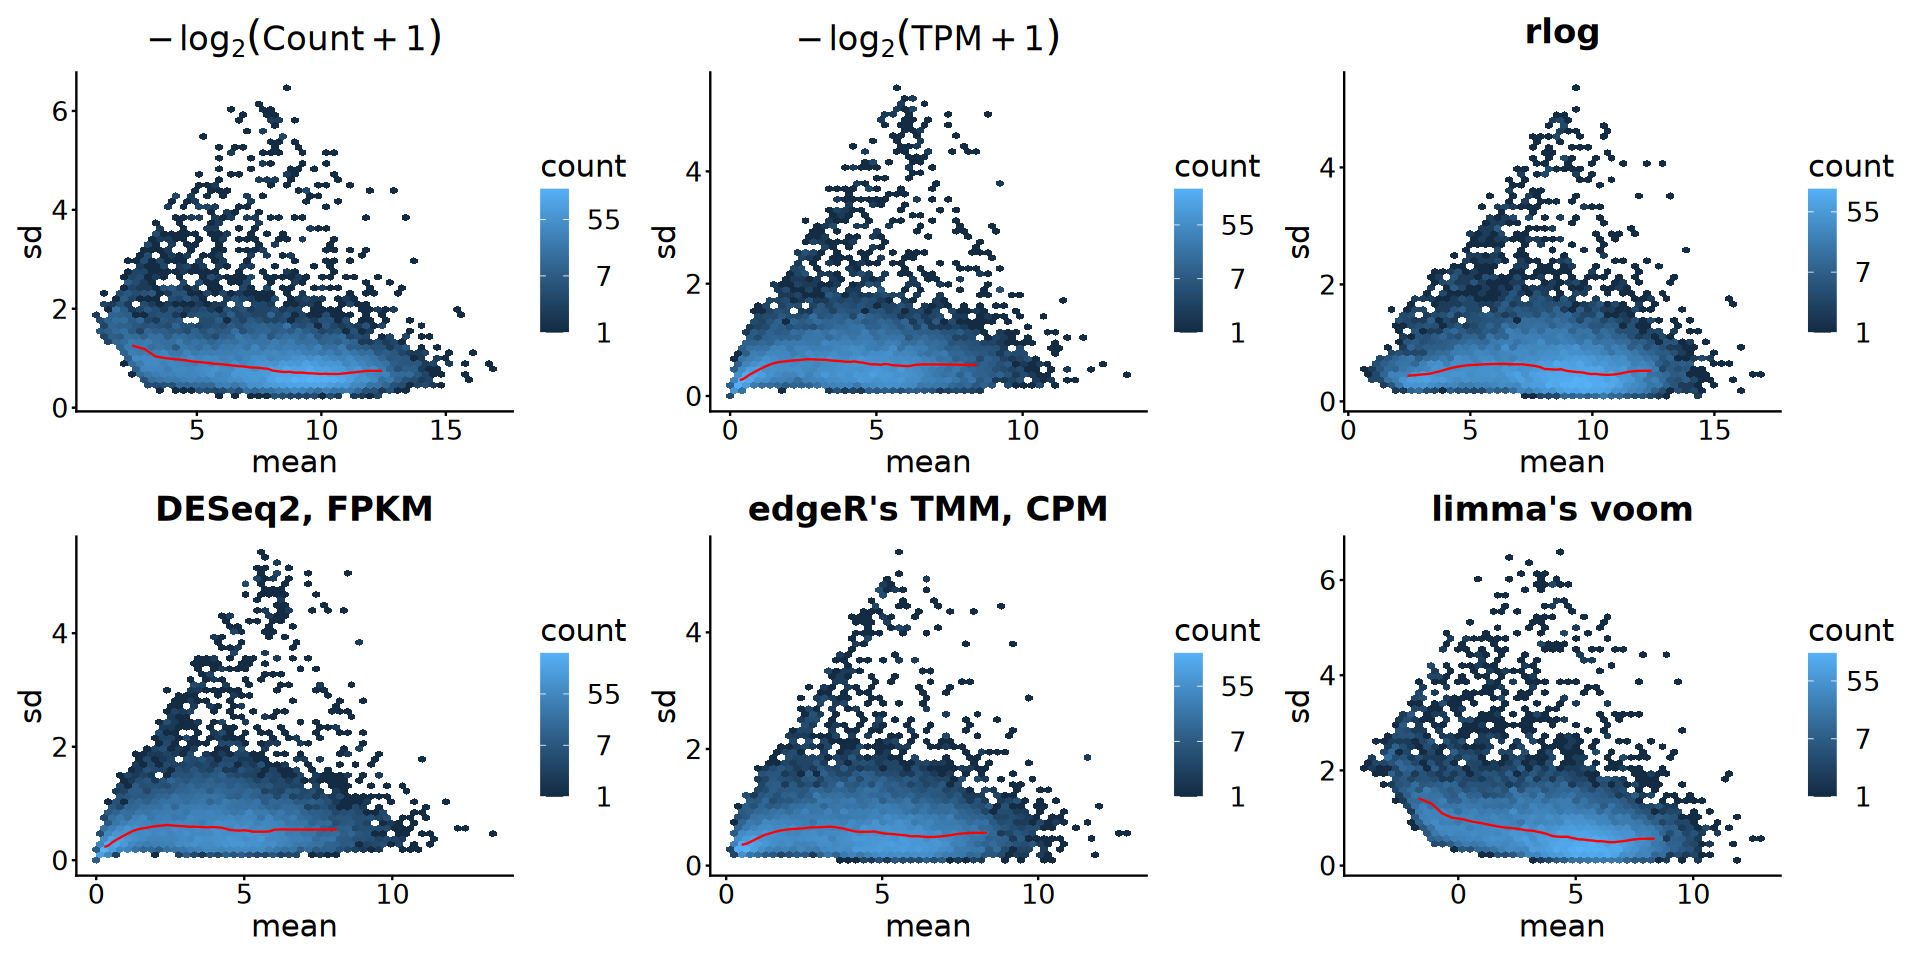

In [28]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [29]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [30]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Fraction, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

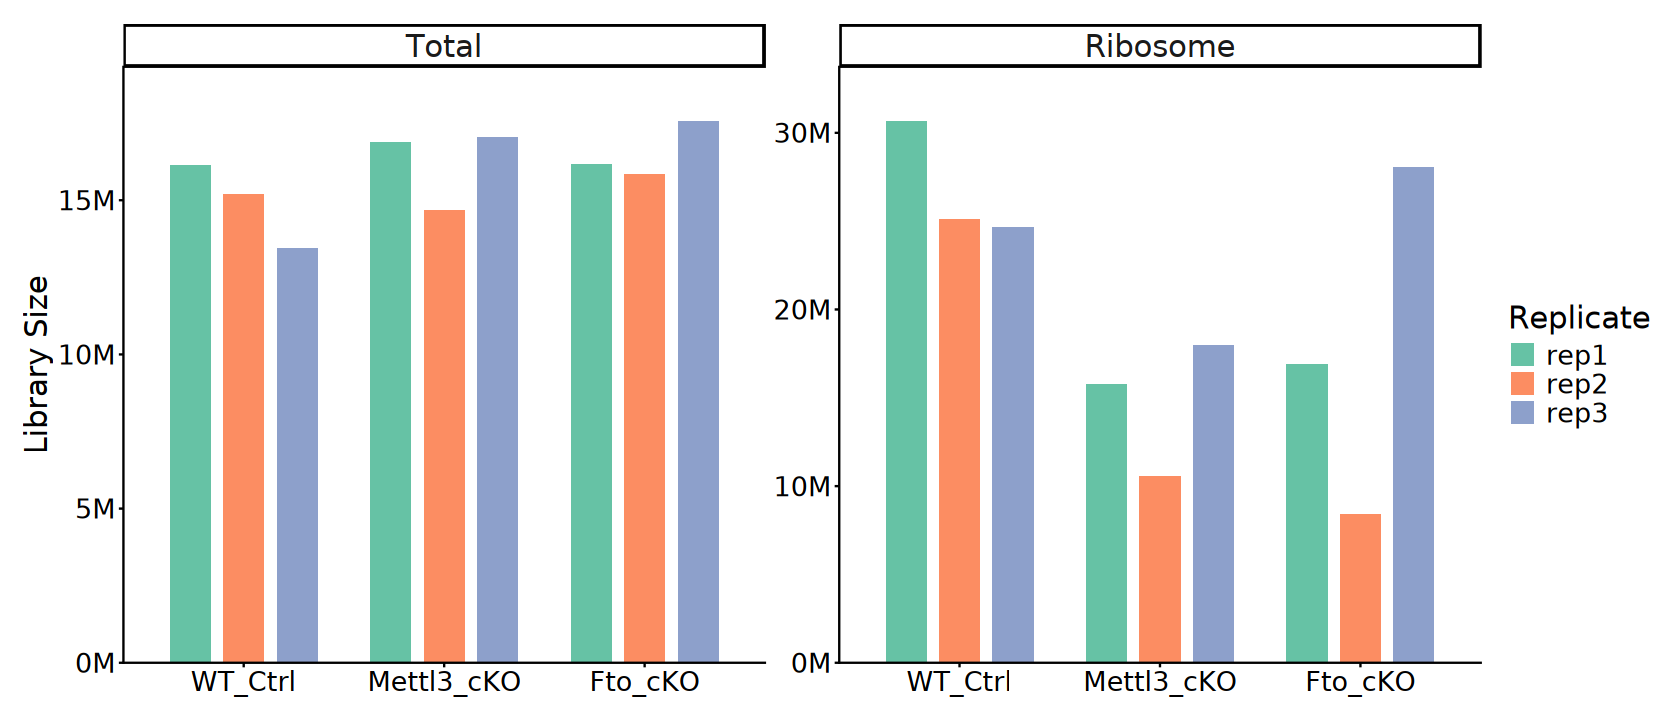

In [31]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free_y") +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [32]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [33]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [34]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [35]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Fraction", "Replicate"), 
    ntop = 1000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [36]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [37]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [38]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

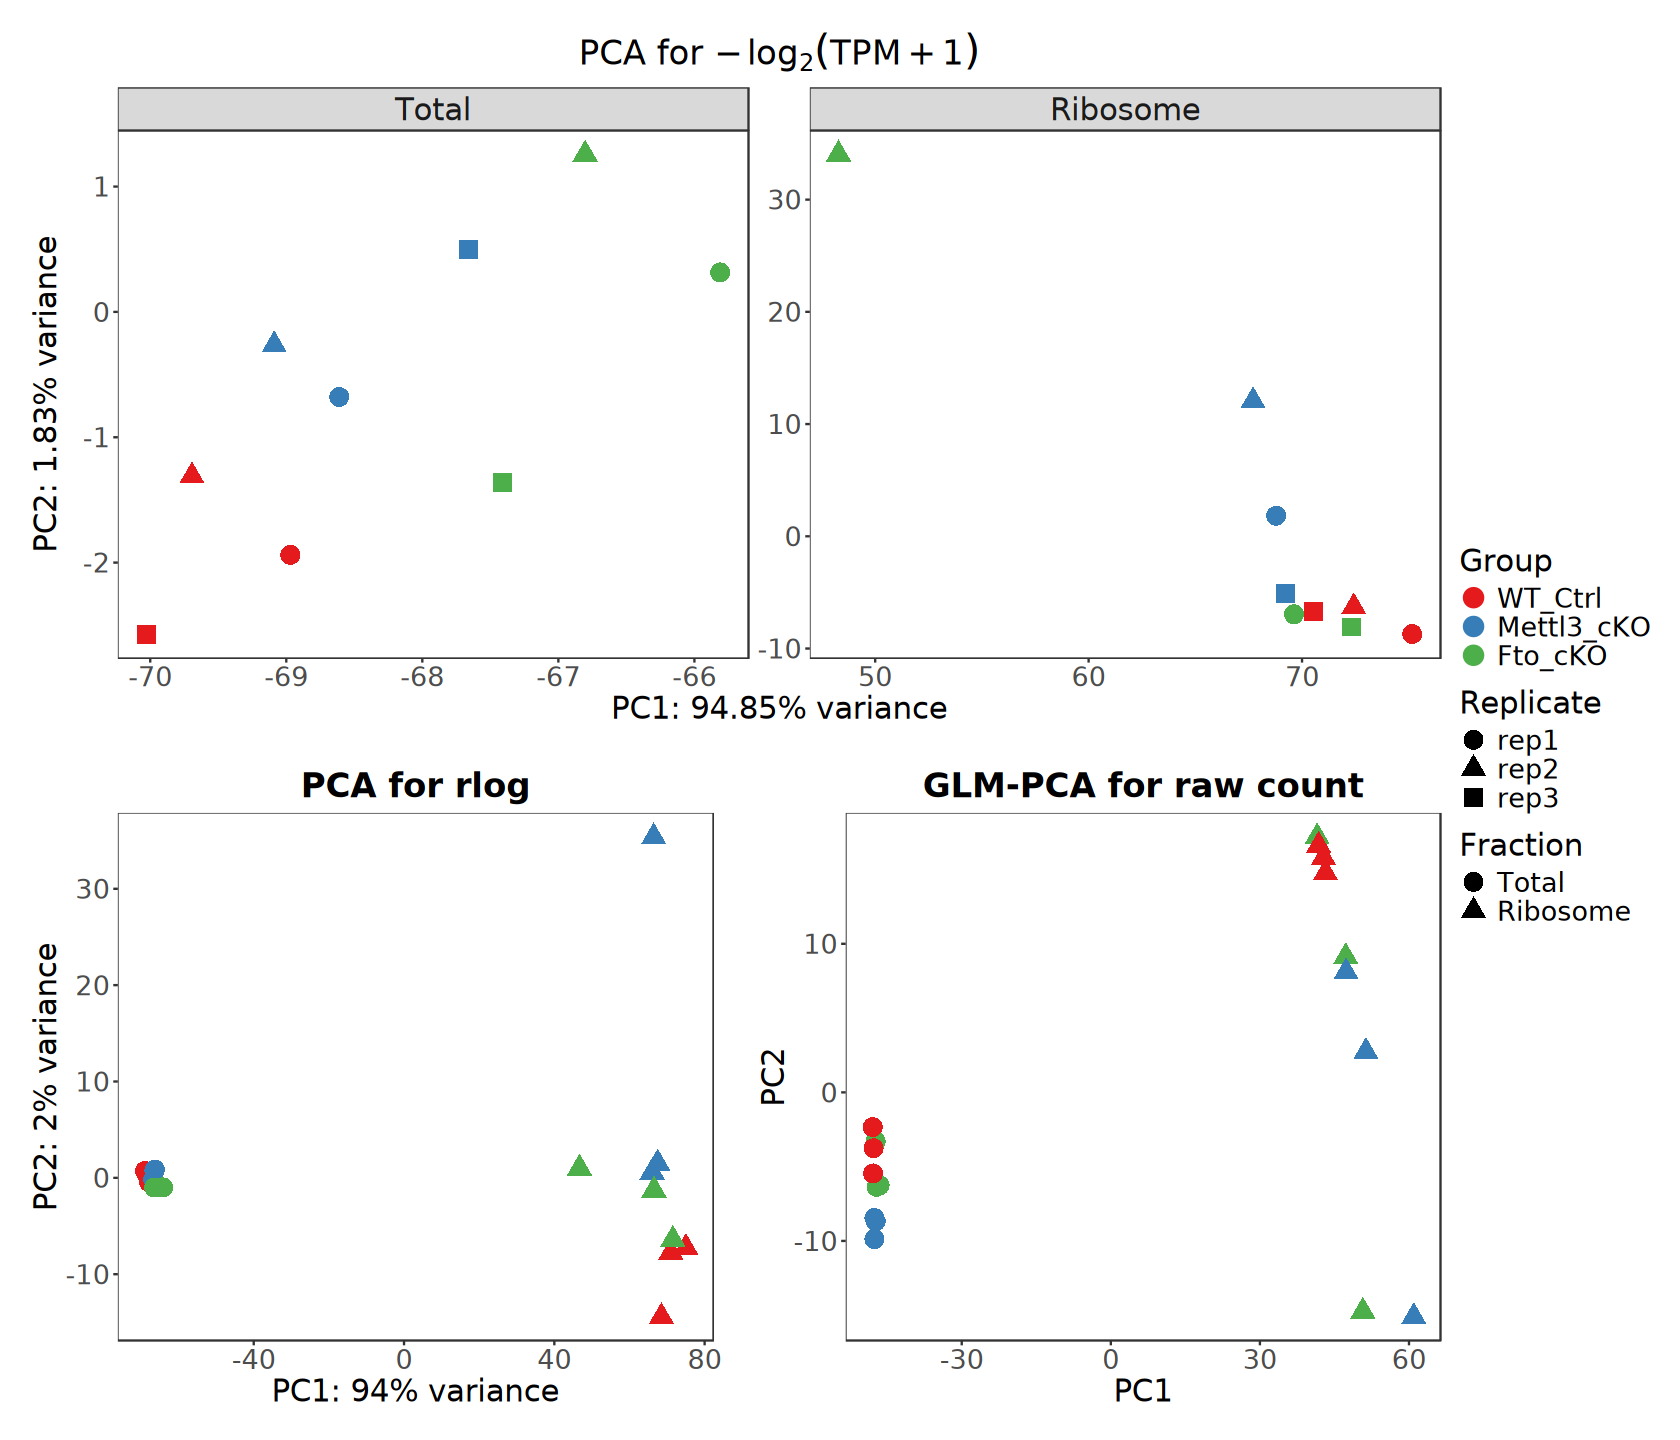

In [39]:
options(repr.plot.width = 14, repr.plot.height = 12)

p1 / (p2 + p3) + plot_layout(nrow = 2, guides = "collect")

## 3). MDS

> Multidimensional scaling

In [40]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

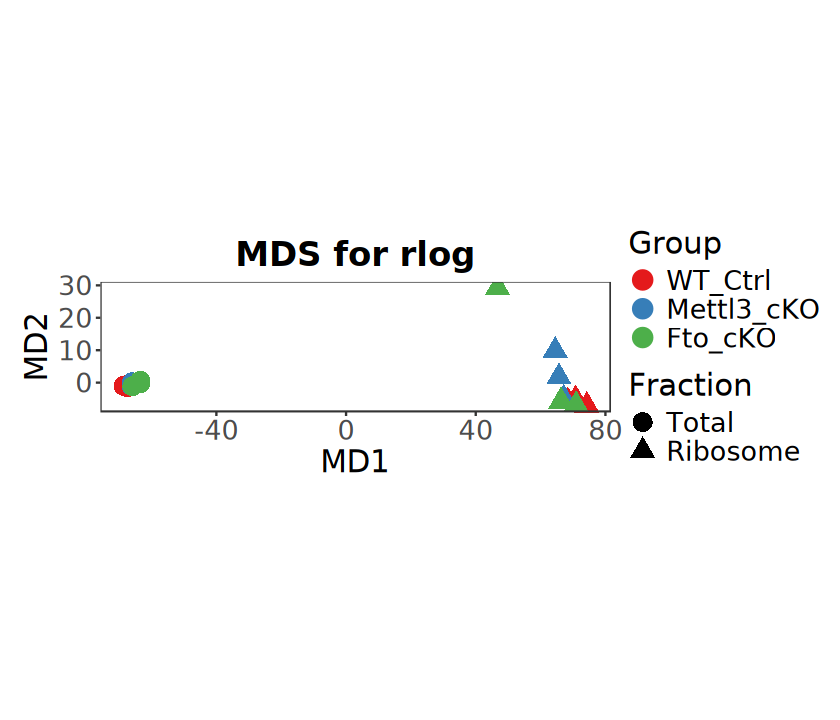

In [41]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 1) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [42]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

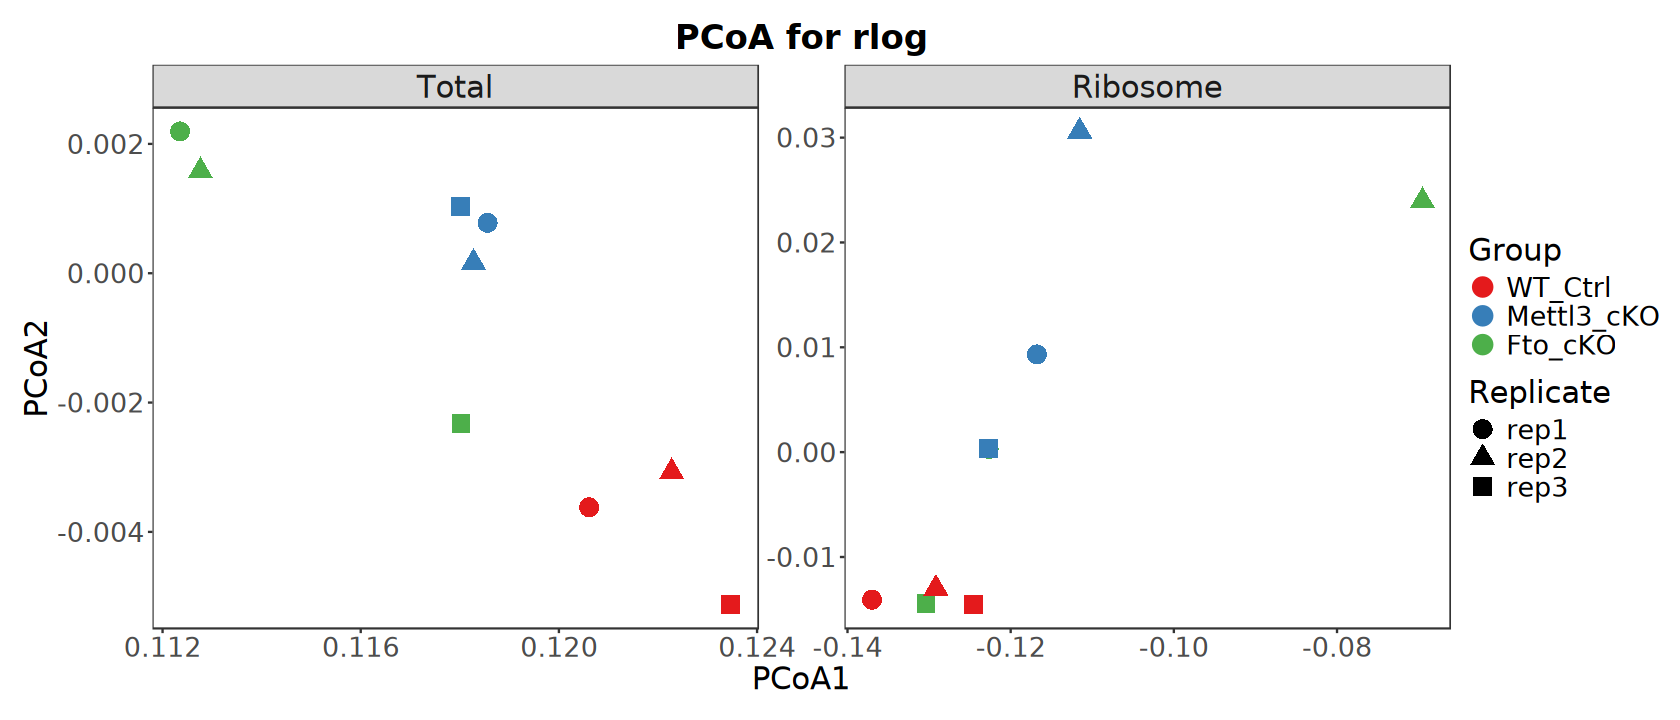

In [43]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [44]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Group)

In [45]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Paired")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Fraction = fraction_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [46]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

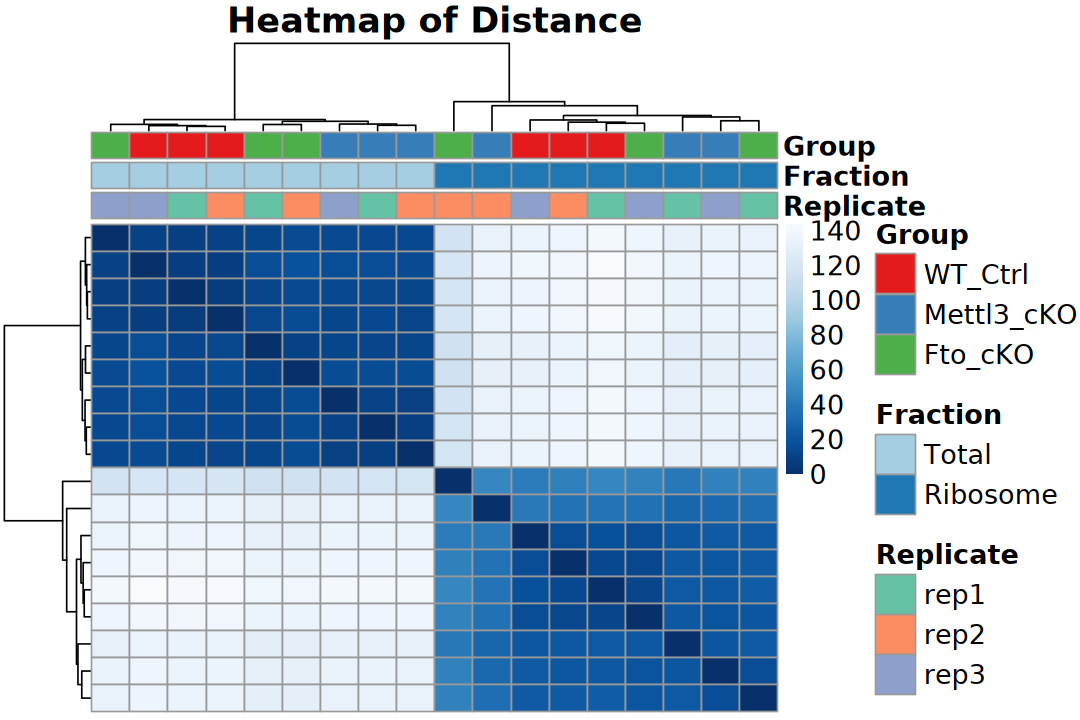

In [47]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [48]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

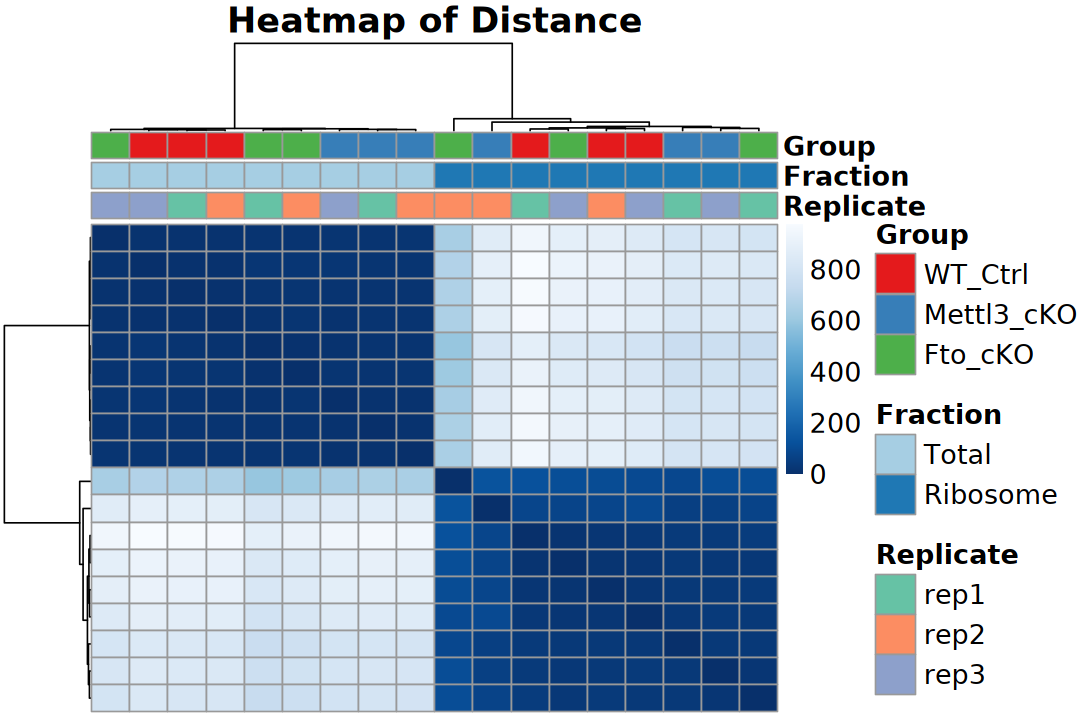

In [49]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [50]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

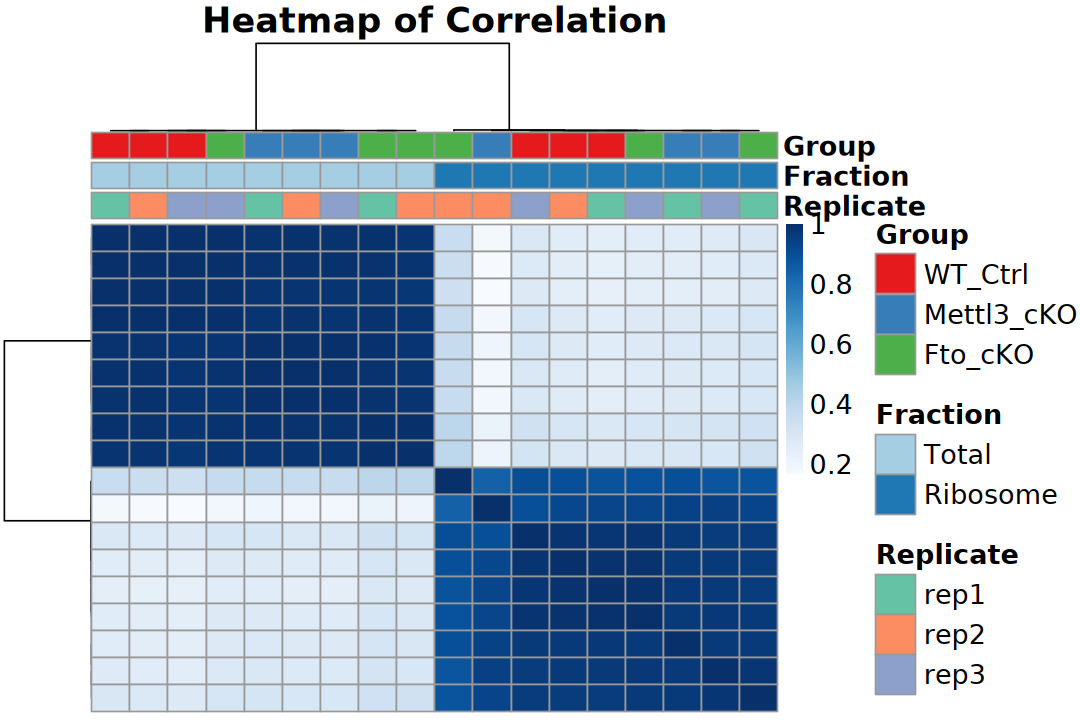

In [51]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

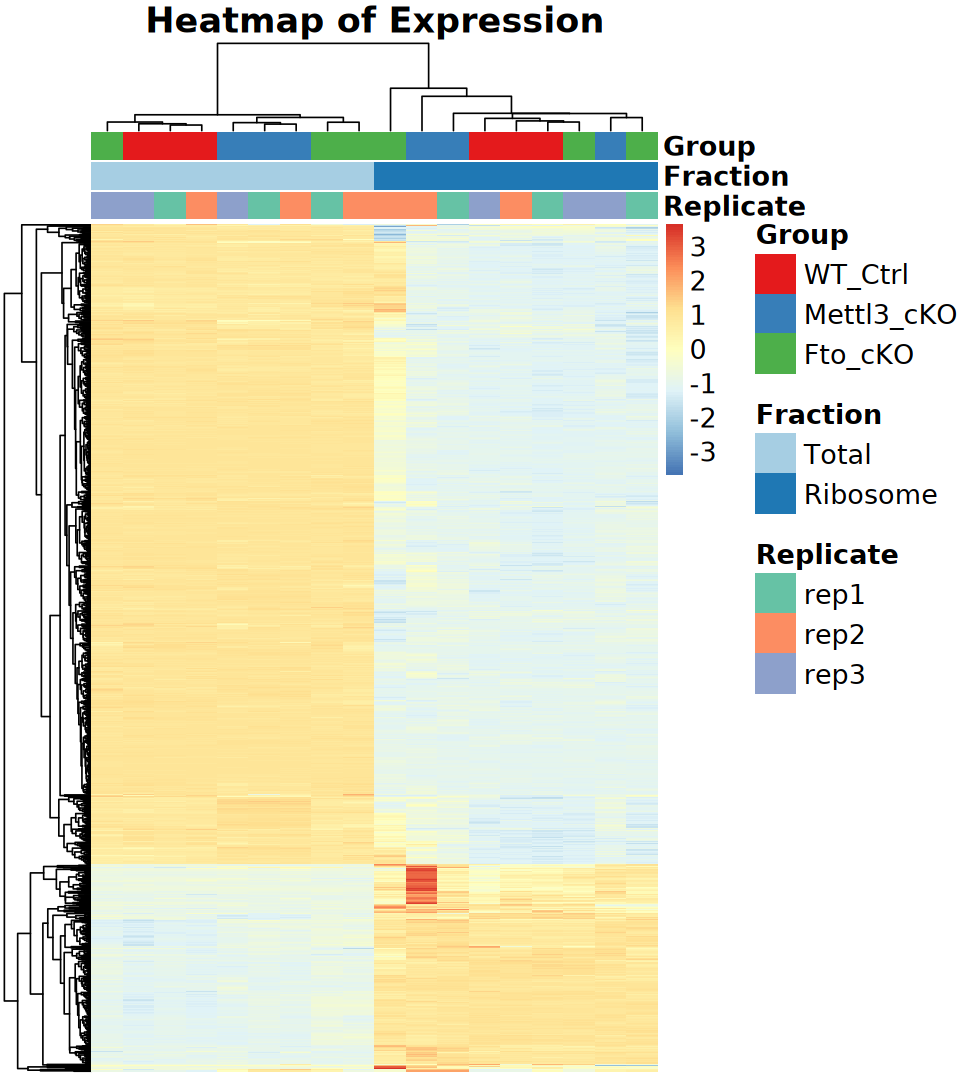

In [52]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. Translation Efficiency

<span style="font-size: 150%">

$$\log_2(\text{TE}) = \log_2\left(\frac{Ribosome\ TPM}{Total\ TPM}\right)$$

$$\log_2(\text{TE}) = \log_2(\text{Ribosome\ TPM}) - \log_2(\text{Total\ TPM})$$

</span>

In [53]:
calculate_log2_te <- function(
    exprmat, coldata, 
    group_col = "Group", group = c("Control", "Treat"), 
    fraction_col = "Fraction", fraction = c("Total", "Ribosome"), 
    replicate_col = "Replicate", replicate = NULL, epsilon = 0) {
    
    # 1. Subset metadata for Total and Ribosome fractions
    total_info <- coldata[coldata[[group_col]] == group & 
        coldata[[fraction_col]] == fraction[1], ]
    ribo_info  <- coldata[coldata[[group_col]] == group & 
        coldata[[fraction_col]] == fraction[2], ]
    
    # 2. Handle biological replicates matching
    if (!is.null(replicate)) {
        if (is.numeric(replicate) && length(replicate) == 1) {
            sample_rep_vals <- as.character(coldata[[replicate_col]])
            replicate_ids <- if (any(grepl("rep", sample_rep_vals))) {
                paste0("rep", 1:replicate)
            } else {
                as.character(1:replicate)
            }
        } else {
            replicate_ids <- as.character(replicate)
        }
    
        total_info <- total_info[total_info[[replicate_col]] %in% replicate_ids, ]
        ribo_info  <- ribo_info[ribo_info[[replicate_col]] %in% replicate_ids, ]

        # Ensure exact matching order of replicates between Total and Ribosome fractions
        ribo_info  <- ribo_info[match(
            total_info[[replicate_col]], ribo_info[[replicate_col]]), ]
    
    }

    # 3. Extract expression matrices and compute log2 Translation Efficiency (TE)
    expr_total <- exprmat[, rownames(total_info), drop = FALSE]
    expr_ribo  <- exprmat[, rownames(ribo_info), drop = FALSE]
    
    log2_te <- log2(expr_ribo + epsilon) - log2(expr_total + epsilon)

    # 4. Construct highly scalable column names automatically
    if (!is.null(replicate)) {
        colnames(log2_te) <- paste0(
            "log2TE_", group, "_", total_info[[replicate_col]])
    } else {
        if (nrow(total_info) == 1) {
            colnames(log2_te) <- paste0("log2TE_", group)
        } else {
            colnames(log2_te) <- paste0(
                "log2TE_", group, "_sample", 1:nrow(total_info))
        }
    }

    # 5. Convert all non-finite values (Inf, -Inf, NaN) to NA
    log2_te[!is.finite(log2_te)] <- NA
    
    return(as.matrix(log2_te))
}

In [54]:
te_ctrl  <- calculate_log2_te(
    tpm, colData(eSet), group = "WT_Ctrl", replicate = 3) |>
    rowMeans(na.rm = TRUE)
te_treat <- calculate_log2_te(
    tpm, colData(eSet), group = "Mettl3_cKO", replicate = 3) |>
    rowMeans(na.rm = TRUE)

te_matrix <- cbind(te_ctrl, te_treat)
te_df <- te_matrix |> as.data.frame() |>
    rownames_to_column("gene_id") |>
    left_join(
        rowData(eSet) |> as.data.frame() |> 
            dplyr::select(-basepairs) |> 
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

head(te_df)

,te_ctrl,te_treat,symbol,type
,<dbl>,<dbl>,<chr>,<chr>
ENSMUSG00000051951.5,0.8853071,1.0459665,Xkr4,protein_coding
ENSMUSG00000025900.12,0.8813569,2.9795936,Rp1,protein_coding
ENSMUSG00000025902.13,-1.8465658,-0.6105532,Sox17,protein_coding
ENSMUSG00000033845.13,0.3186960,0.3803450,Mrpl15,protein_coding
ENSMUSG00000025903.14,-0.3829118,-0.4338377,Lypla1,protein_coding
ENSMUSG00000033813.15,-0.4578084,-1.2583139,Tcea1,protein_coding


In [55]:
# 1. Create logical matrices to identify infinite and missing/NaN values
has_inf <- is.infinite(te_df$te_ctrl) | is.infinite(te_df$te_treat)
has_nan_or_na <- is.na(te_df$te_ctrl) | is.na(te_df$te_treat)

# 2. Combine conditions: a row is marked TRUE if it contains any abnormal value
rows_with_abnormal <- has_inf | has_nan_or_na

# 3. Extract rows containing abnormal values
abnormal_data <- te_df[rows_with_abnormal, , drop = FALSE]

# 4. Output results to the console
if (nrow(abnormal_data) > 0) {
    cat("Warning: Found", nrow(abnormal_data), "row(s) with abnormal values:\n")
    print(head(abnormal_data, 10))
} else {
    cat("Success: No Inf, -Inf, NaN, or NA values detected in the table.\n")
}

# Keep only rows that do not contain any abnormal values
# te_df <- te_df[!rows_with_abnormal, , drop = FALSE]

                        te_ctrl  te_treat        symbol           type
ENSMUSG00000073722.3        NaN       NaN 4931408C20Rik protein_coding
ENSMUSG00000026070.15  2.061230       NaN        Il18r1 protein_coding
ENSMUSG00000050296.14  1.195821       NaN        Abca12 protein_coding
ENSMUSG00000055197.4        NaN       NaN           Fev protein_coding
ENSMUSG00000089844.7        NaN       NaN A530032D15Rik protein_coding
ENSMUSG00000070031.11 -3.974891       NaN         Sp140 protein_coding
ENSMUSG00000078193.2        NaN -6.501419        Gm2000 protein_coding
ENSMUSG00000071890.4        NaN       NaN         Mroh9 protein_coding
ENSMUSG00000026523.14       NaN       NaN         Wdr64 protein_coding
ENSMUSG00000043429.7        NaN  2.867132       Ccdc185 protein_coding


# 6. DTEGs

In [56]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

<span style="font-size: 150%">

$$\log_2\text{FC} = \log_2\left( \frac{\text{ribo}_{\text{treat}}}{\text{Total}_{\text{treat}}} \right) - \log_2\left( \frac{\text{ribo}_{\text{ctrl}}}{\text{Total}_{\text{ctrl}}} \right)$$

</span>

In [57]:
design(dds)

~Group * Fraction

In [58]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [59]:
resultsNames(dds)

[1] "Intercept"                        "Group_Mettl3_cKO_vs_WT_Ctrl"     
[3] "Group_Fto_cKO_vs_WT_Ctrl"         "Fraction_Ribosome_vs_Total"      
[5] "GroupMettl3_cKO.FractionRibosome" "GroupFto_cKO.FractionRibosome"

### a). Standard

In [60]:
# Examining whether treatment responses differ between the two cell types
res <- results(
    dds, name = "GroupMettl3_cKO.FractionRibosome",
    lfcThreshold = logfc_cutoff, alpha = p_cutoff)

summary(res)


out of 14783 with nonzero total read count
adjusted p-value < 0.05
LFC > 0.26 (up)    : 5, 0.034%
LFC < -0.26 (down) : 1, 0.0068%
outliers [1]       : 188, 1.3%
low counts [2]     : 0, 0%
(mean count < 2)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [61]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
    5     1 14777 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,135.34514,0.03825519,0.4362306,0.08769488,0.94170773,0.9999487,NS,Xkr4,protein_coding,1941
ENSMUSG00000025900.12,10.27003,2.15713401,1.1428407,1.88751935,0.06582445,0.9999487,NS,Rp1,protein_coding,9602
ENSMUSG00000025902.13,56.91027,1.09003574,0.4692847,2.32276013,0.04098065,0.9298699,NS,Sox17,protein_coding,1369
ENSMUSG00000033845.13,1002.59956,-0.02025836,0.3287194,-0.06162812,0.96430696,0.9999487,NS,Mrpl15,protein_coding,1025
ENSMUSG00000025903.14,162.63500,-0.17251377,0.3296860,-0.52326686,0.70140925,0.9999487,NS,Lypla1,protein_coding,747
ENSMUSG00000033813.15,1282.88553,-0.87386715,0.2885231,-3.02875949,0.01716629,0.7118039,NS,Tcea1,protein_coding,999


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [62]:
# Examining whether treatment responses differ between the two cell types
res_lfc <- lfcShrink(dds, coef = "GroupMettl3_cKO.FractionRibosome", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 14783 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 128, 0.87%
LFC < 0 (down)     : 65, 0.44%
outliers [1]       : 188, 1.3%
low counts [2]     : 0, 0%
(mean count < 2)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [63]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
   43    30 14710 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,135.34514,0.003417611,0.1284814,0.930119191,0.9920909,NS,Xkr4,protein_coding,1941
ENSMUSG00000025900.12,10.27003,0.031255454,0.1388155,0.059090506,0.5161935,NS,Rp1,protein_coding,9602
ENSMUSG00000025902.13,56.91027,0.104194429,0.1911814,0.020192042,0.3414007,NS,Sox17,protein_coding,1369
ENSMUSG00000033845.13,1002.59956,-0.002387356,0.1244055,0.950858983,0.9947042,NS,Mrpl15,protein_coding,1025
ENSMUSG00000025903.14,162.63500,-0.025444658,0.1273144,0.600788563,0.9391127,NS,Lypla1,protein_coding,747
ENSMUSG00000033813.15,1282.88553,-0.633210358,0.3495756,0.002455601,0.1389274,NS,Tcea1,protein_coding,999


In [64]:
comparison_df <- deseq2_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_raw = result) |> 
    inner_join(
        deseq2_lfc_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_lfc = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    Raw = comparison_df$result_raw, 
    LFC_Shrink = comparison_df$result_lfc))


      LFC_Shrink
Raw       Up  Down    NS
  Up       5     0     0
  Down     0     1     0
  NS      38    29 14710


## 2). edgeR

> Trimmed Mean of M-values (TMM)

### a). Negative binomial GLM framework

In [65]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
colnames(design)

[1] "(Intercept)"                      "GroupMettl3_cKO"                 
[3] "GroupFto_cKO"                     "FractionRibosome"                
[5] "GroupMettl3_cKO:FractionRibosome" "GroupFto_cKO:FractionRibosome"

In [66]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [67]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = "GroupMettl3_cKO:FractionRibosome")

In [68]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
   41    14 14551 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000021495.10,Fam193b,protein_coding,2676,1.288850,6.679521,35.76624,2.224695e-09,3.249389e-05,Up
ENSMUSG00000038965.17,Ube2l3,protein_coding,541,1.948755,5.823899,32.12275,1.447327e-08,1.056983e-04,Up
ENSMUSG00000035745.9,Grin3b,protein_coding,3033,3.323809,1.735207,24.00581,9.604546e-07,3.503864e-03,Up
ENSMUSG00000038199.12,Iqca1l,protein_coding,2547,3.311708,-0.147009,23.95158,9.878910e-07,3.503864e-03,Up
ENSMUSG00000078486.3,Perm1,protein_coding,2421,2.064975,2.763995,23.45528,1.278510e-06,3.503864e-03,Up
ENSMUSG00000040701.16,Ap1g2,protein_coding,2373,1.305222,3.932697,23.22736,1.439352e-06,3.503864e-03,Up


### b). Quasi-likelihood pipeline (edgeR v3)

In [69]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)

In [70]:
dgel_nbglm <- estimateDisp(dgel, design)

In [71]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = "GroupMettl3_cKO:FractionRibosome")

In [72]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
    1     0 14605 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000021495.10,Fam193b,protein_coding,2676,1.2888552,6.679521,48.66632,2.909857e-06,0.04250138,Up
ENSMUSG00000040701.16,Ap1g2,protein_coding,2373,1.3038145,3.932697,33.29138,2.732221e-05,0.10969718,NS
ENSMUSG00000038965.17,Ube2l3,protein_coding,541,1.9582377,5.823899,32.96422,2.914049e-05,0.10969718,NS
ENSMUSG00000022160.18,Mettl3,protein_coding,1756,-0.9887381,5.908985,32.72544,3.004168e-05,0.10969718,NS
ENSMUSG00000078486.3,Perm1,protein_coding,2421,2.0651604,2.763995,27.27751,8.154778e-05,0.17771078,NS
ENSMUSG00000042138.8,Msantd2,protein_coding,1725,0.9783817,5.341970,26.87763,8.679400e-05,0.17771078,NS


In [73]:
comparison_df <- edger_glm_lrt_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, glm_lrt = result) |> 
    inner_join(
        edger_glm_qlf_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, glm_qlf = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    glm_lrt = comparison_df$glm_lrt, 
    glm_qlf = comparison_df$glm_qlf))


       glm_qlf
glm_lrt    Up  Down    NS
   Up       1     0    40
   Down     0     0    14
   NS       0     0 14551


## 3). limma-voom

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [74]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)

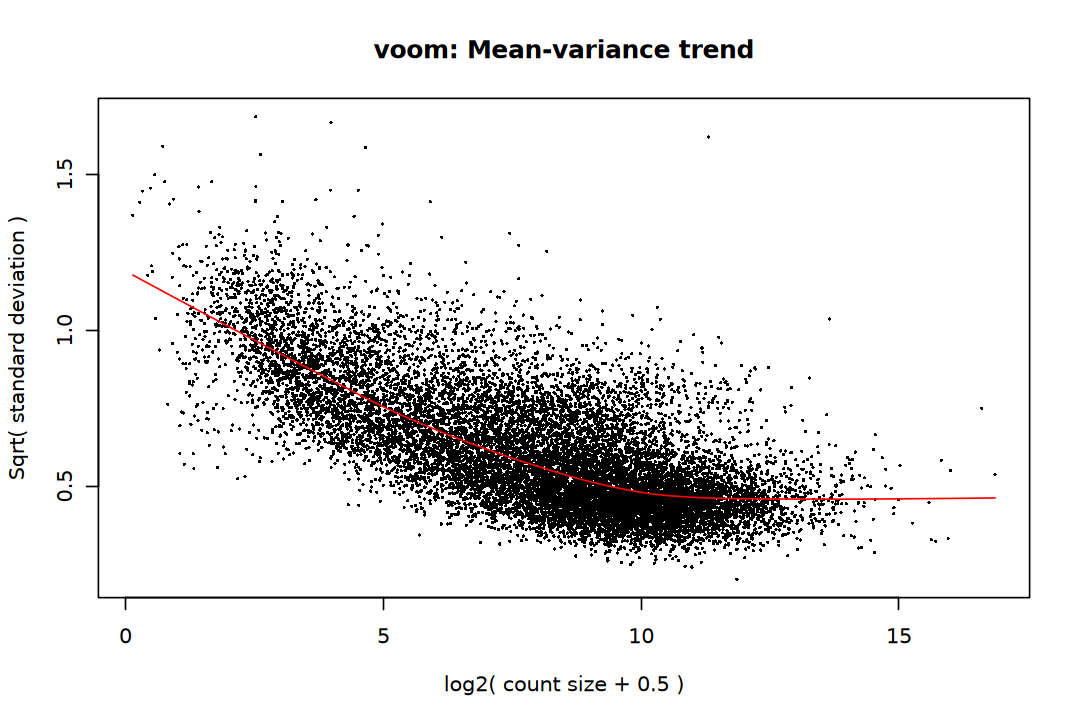

In [75]:
options(repr.plot.width = 9, repr.plot.height = 6)
norm_v <- voom(dgel, design, plot = TRUE)

In [76]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [77]:
limma_voom_result <- topTable(efit, coef = "GroupMettl3_cKO:FractionRibosome", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
    1     0 14605 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000021495.10,Fam193b,protein_coding,2676,1.2837668,6.373146,7.324210,1.339762e-06,0.01956856,5.457601,Up
ENSMUSG00000022160.18,Mettl3,protein_coding,1756,-0.9842307,5.869770,-5.849563,2.093359e-05,0.15287801,2.950573,NS
ENSMUSG00000040701.16,Ap1g2,protein_coding,2373,1.2792651,3.621565,5.489574,4.280498e-05,0.17344302,2.050495,NS
ENSMUSG00000042138.8,Msantd2,protein_coding,1725,0.9772319,5.272279,5.266465,6.723116e-05,0.18462629,1.869395,NS
ENSMUSG00000036241.3,Ube2r2,protein_coding,714,-0.8132436,7.504051,-5.176308,8.082355e-05,0.18462629,1.710438,NS
ENSMUSG00000036036.15,Zfp57,protein_coding,1263,0.8534763,7.699115,5.132144,8.848309e-05,0.18462629,1.624851,NS


In [78]:
comparison_df <- limma_voom_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, limma = result) |> 
    inner_join(
        edger_glm_qlf_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    limma = comparison_df$limma, 
    edger = comparison_df$edger))


      edger
limma     Up  Down    NS
  Up       1     0     0
  Down     0     0     0
  NS       0     0 14605


## DEGs Evaluation

In [79]:
add_label <- function(res, symbol_col = "symbol", type_col = "type") {
    res |> rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            valid = .data[[type_col]] == "protein_coding" & 
                result %in% c("Up", "Down"),
            label = dplyr::if_else(
                valid & cumsum(valid) <= 5, 
                .data[[symbol_col]], NA_character_)
        ) |>
        dplyr::ungroup() |>
        column_to_rownames("gene_id")
}

In [80]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_lrt_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [81]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [82]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

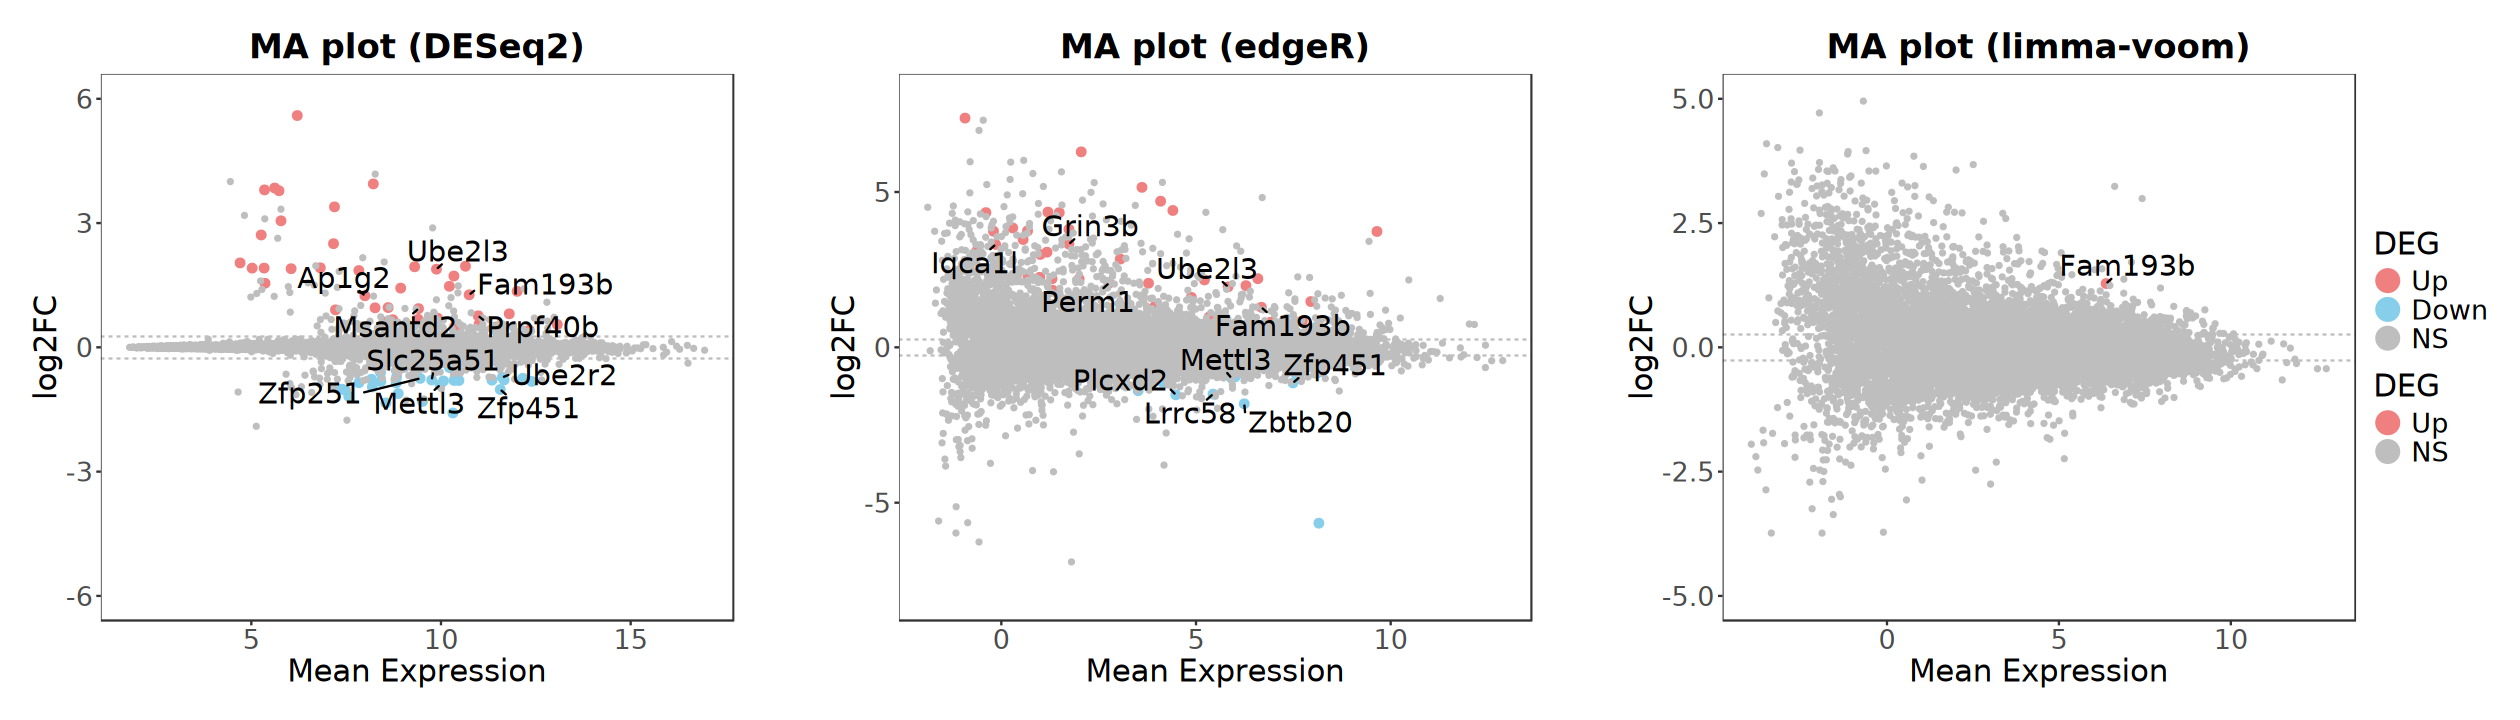

In [83]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [84]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [85]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

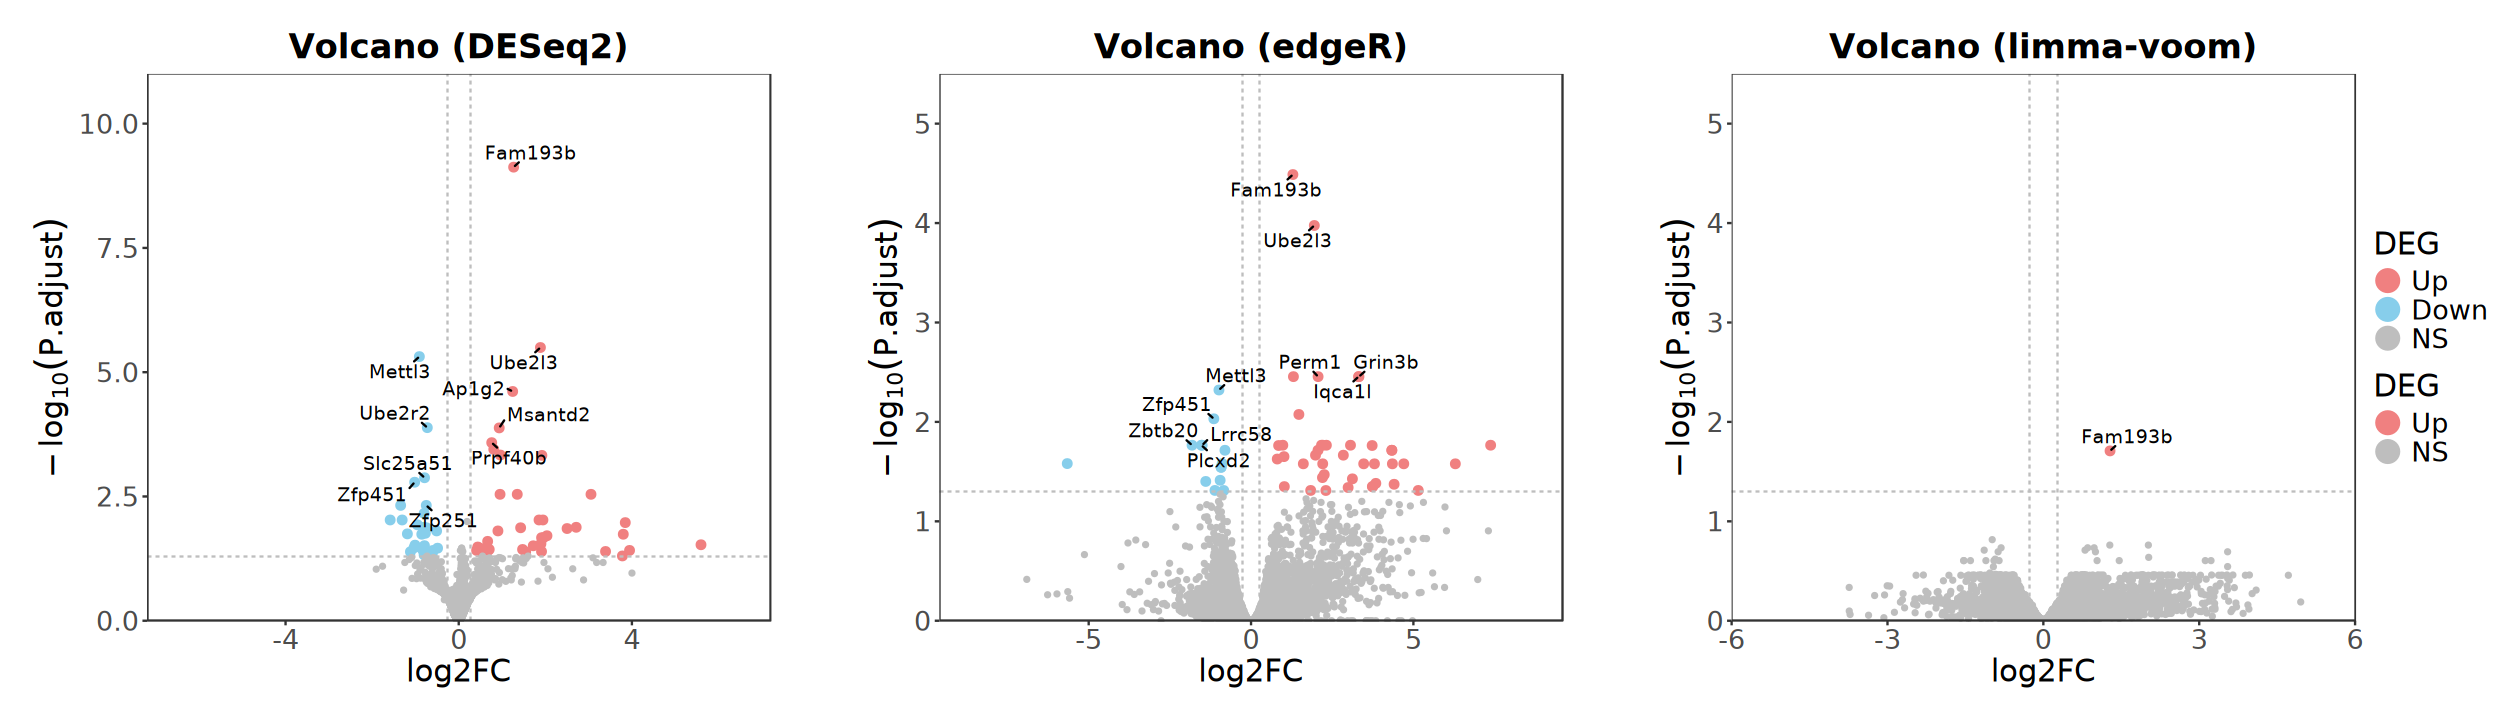

In [86]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [87]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [88]:
genes_up <- list(
    DESeq2 = deseq2_result[deseq2_result$result == "Up", "symbol"], 
    edgeR = edger_result[edger_result$result == "Up", "symbol"], 
    limma = limma_result[limma_result$result == "Up", "symbol"])
genes_up <- lapply(genes_up, unique)

In [89]:
genes_down <- list(
    DESeq2 = deseq2_result[deseq2_result$result == "Down", "symbol"], 
    edgeR = edger_result[edger_result$result == "Down", "symbol"], 
    limma = limma_result[limma_result$result == "Down", "symbol"])
genes_down <- lapply(genes_down, unique)

In [90]:
p1 <- ggVennDiagram(genes_up, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(genes_down, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

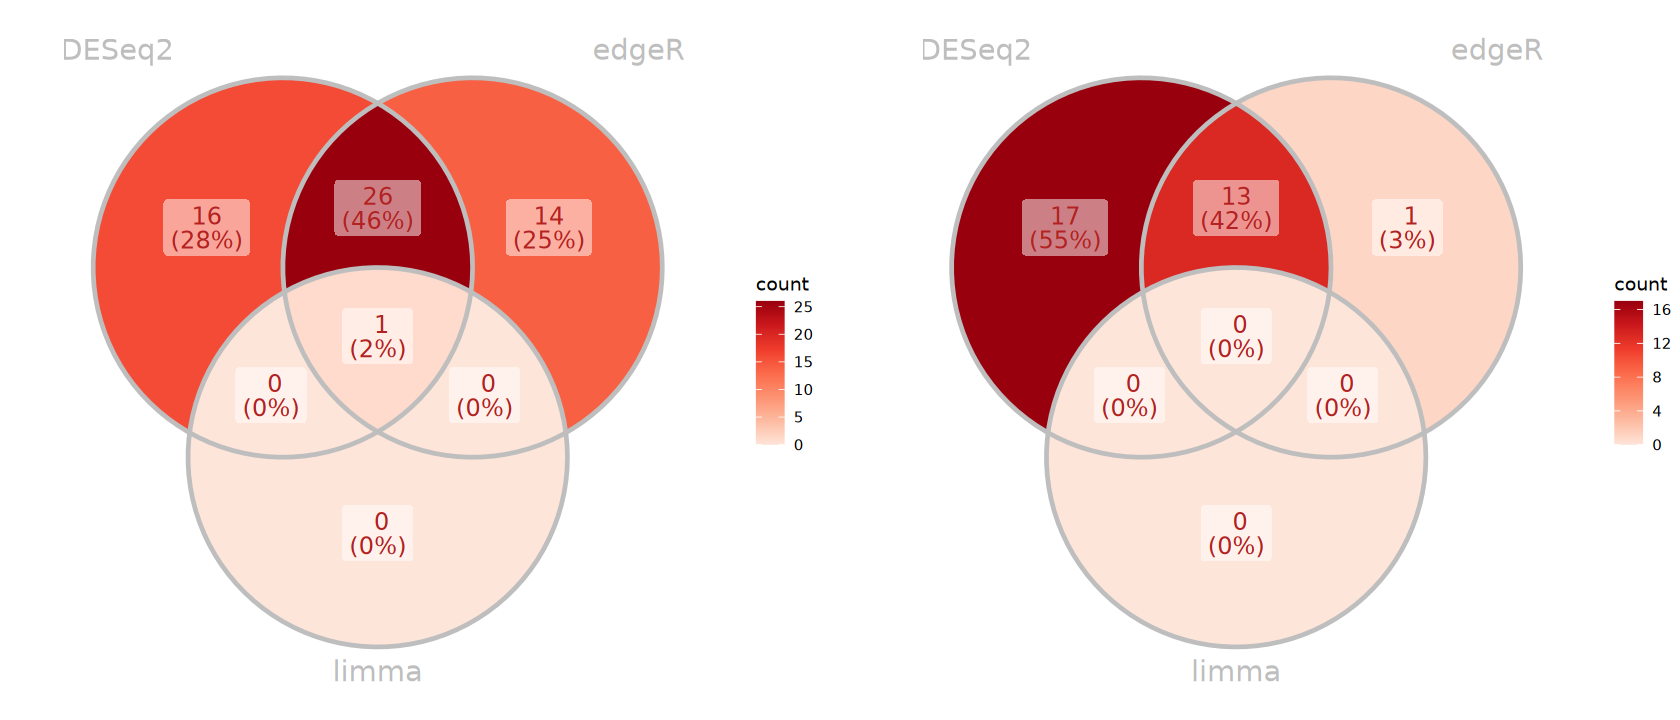

In [91]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Visualization

In [92]:
degs_result <- left_join(
    deseq2_result |> rownames_to_column("gene_id"), 
    te_matrix |> as.data.frame() |> rownames_to_column("gene_id"), 
    by = "gene_id") |>
    column_to_rownames("gene_id")

head(degs_result)

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,valid,label,te_ctrl,te_treat
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<lgl>,<chr>,<dbl>,<dbl>
ENSMUSG00000021495.10,1712.4094,1.2680679,0.1779199,5.139521e-14,7.501131e-10,Up,Fam193b,protein_coding,2676,TRUE,Fam193b,-2.3735454,-0.96160363
ENSMUSG00000038965.17,941.7499,1.8870352,0.3260827,4.363881e-10,3.184542e-06,Up,Ube2l3,protein_coding,541,TRUE,Ube2l3,-6.8209138,-4.69662750
ENSMUSG00000040701.16,253.8497,1.2459755,0.2372828,6.688024e-09,2.440293e-05,Up,Ap1g2,protein_coding,2373,TRUE,Ap1g2,-2.3215973,-0.89520549
ENSMUSG00000042138.8,678.3614,0.9350962,0.1917554,5.425850e-08,1.319838e-04,Up,Msantd2,protein_coding,1725,TRUE,Msantd2,-1.0338635,0.07450338
ENSMUSG00000023007.15,2019.6964,0.7620382,0.1638499,1.253075e-07,2.612661e-04,Up,Prpf40b,protein_coding,2622,TRUE,Prpf40b,-0.9836895,-0.05258944
ENSMUSG00000036036.15,3565.1079,0.8094822,0.1749149,1.952902e-07,3.562826e-04,Up,Zfp57,protein_coding,1263,TRUE,NA,-0.6504997,0.32992358


In [93]:
# 1. Create logical matrices to identify infinite and missing/NaN values
has_inf <- is.infinite(degs_result$te_ctrl) | is.infinite(degs_result$te_treat)
has_nan_or_na <- is.na(degs_result$te_ctrl) | is.na(degs_result$te_treat)

# 2. Combine conditions: a row is marked TRUE if it contains any abnormal value
rows_with_abnormal <- has_inf | has_nan_or_na

# 3. Extract rows containing abnormal values
abnormal_data <- degs_result[rows_with_abnormal, , drop = FALSE]

print(table(abnormal_data$result))

# 4. Output results to the console
if (nrow(abnormal_data[abnormal_data$result %in% c("Up", "Down"), ]) > 0) {
    cat("Warning: Found", nrow(abnormal_data), "row(s) with abnormal values:\n")
    print(abnormal_data[
        abnormal_data$result %in% c("Up", "Down"), 
        c("logFC", "pvalue", "padj", "result", "symbol", "te_ctrl", "te_treat")])
} else {
    cat("Success: No Inf, -Inf, NaN, or NA values detected in the table.\n")
}


  Up Down   NS 
   0    0  219 
Success: No Inf, -Inf, NaN, or NA values detected in the table.


### Scatter Plot

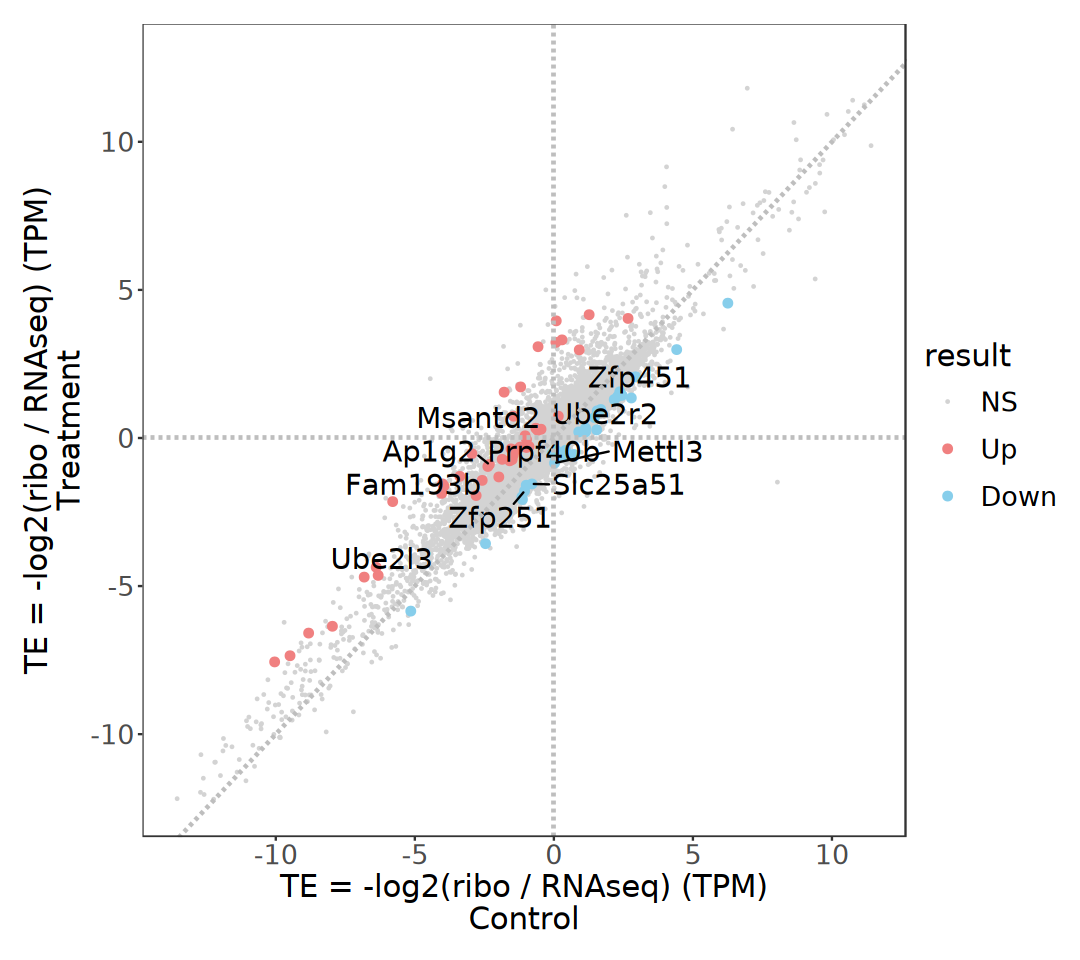

In [94]:
options(repr.plot.width = 9, repr.plot.height = 8)

# axisRange <- c(degs_result$te_ctrl, degs_result$te_treat) |> 
#     na.omit() %>% .[is.finite(.)] |> abs() |> max(na.rm = T) |> ceiling()

ggplot(degs_result, aes(x = te_ctrl, y = te_treat)) +
    geom_point(
        data = subset(degs_result, result == "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_point(
        data = subset(degs_result, result != "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_text_repel(
        aes(label = label),  na.rm = TRUE, size = 6, 
        color = "black", max.overlaps = Inf) +
    geom_hline(
        yintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    # xlim(-axisRange, axisRange) + 
    # ylim(-axisRange, axisRange) + 
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "LightGray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 0.3))+
    labs(x = "TE = -log2(ribo / RNAseq) (TPM)\n Control ", 
         y = "TE = -log2(ribo / RNAseq) (TPM)\n Treatment ") + 
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [95]:
design(dds)
resultsNames(dds)

~Group * Fraction

[1] "Intercept"                        "Group_Mettl3_cKO_vs_WT_Ctrl"     
[3] "Group_Fto_cKO_vs_WT_Ctrl"         "Fraction_Ribosome_vs_Total"      
[5] "GroupMettl3_cKO.FractionRibosome" "GroupFto_cKO.FractionRibosome"

In [96]:
# 1. Extract results from DESeq2
res_total <- results(dds, name = "Group_Mettl3_cKO_vs_WT_Ctrl")
res_ribo <- results(dds, contrast = list(
    c("Group_Mettl3_cKO_vs_WT_Ctrl", "GroupMettl3_cKO.FractionRibosome")))

In [97]:
# 2. Match and map log2FoldChange columns directly using row names
degs_result$log2FC_total  <- res_total[rownames(degs_result), "log2FoldChange"]
degs_result$log2FC_ribo <- res_ribo[rownames(degs_result), "log2FoldChange"]

head(degs_result)

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,valid,label,te_ctrl,te_treat,log2FC_total,log2FC_ribo
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<lgl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ENSMUSG00000021495.10,1712.4094,1.2680679,0.1779199,5.139521e-14,7.501131e-10,Up,Fam193b,protein_coding,2676,TRUE,Fam193b,-2.3735454,-0.96160363,-0.3825859,0.93248088
ENSMUSG00000038965.17,941.7499,1.8870352,0.3260827,4.363881e-10,3.184542e-06,Up,Ube2l3,protein_coding,541,TRUE,Ube2l3,-6.8209138,-4.69662750,0.2131846,2.19820712
ENSMUSG00000040701.16,253.8497,1.2459755,0.2372828,6.688024e-09,2.440293e-05,Up,Ap1g2,protein_coding,2373,TRUE,Ap1g2,-2.3215973,-0.89520549,-0.6689974,0.66070296
ENSMUSG00000042138.8,678.3614,0.9350962,0.1917554,5.425850e-08,1.319838e-04,Up,Msantd2,protein_coding,1725,TRUE,Msantd2,-1.0338635,0.07450338,-0.3558556,0.64978162
ENSMUSG00000023007.15,2019.6964,0.7620382,0.1638499,1.253075e-07,2.612661e-04,Up,Prpf40b,protein_coding,2622,TRUE,Prpf40b,-0.9836895,-0.05258944,-0.1707277,0.66353971
ENSMUSG00000036036.15,3565.1079,0.8094822,0.1749149,1.952902e-07,3.562826e-04,Up,Zfp57,protein_coding,1263,TRUE,NA,-0.6504997,0.32992358,-0.7980817,0.07803265


In [98]:
# colnames(design)

# # 1. Extract results from edgeR
# fit <- glmQLFit(dgel_nbglm, design)
# qlf <- glmQLFTest(fit, coef = "GroupMettl3_cKO")
# res_total <- topTags(qlf, n = Inf)$table

# qlf <- glmQLFTest(fit, contrast = c(0, 1, 0, 1))
# res_ribo <- topTags(qlf, n = Inf)$table

# # 2. Match and map log2FoldChange columns directly using row names
# degs_result$log2FC_total  <- res_total[rownames(degs_result), "logFC"]
# degs_result$log2FC_ribo <- res_ribo[rownames(degs_result), "logFC"]

# head(degs_result)

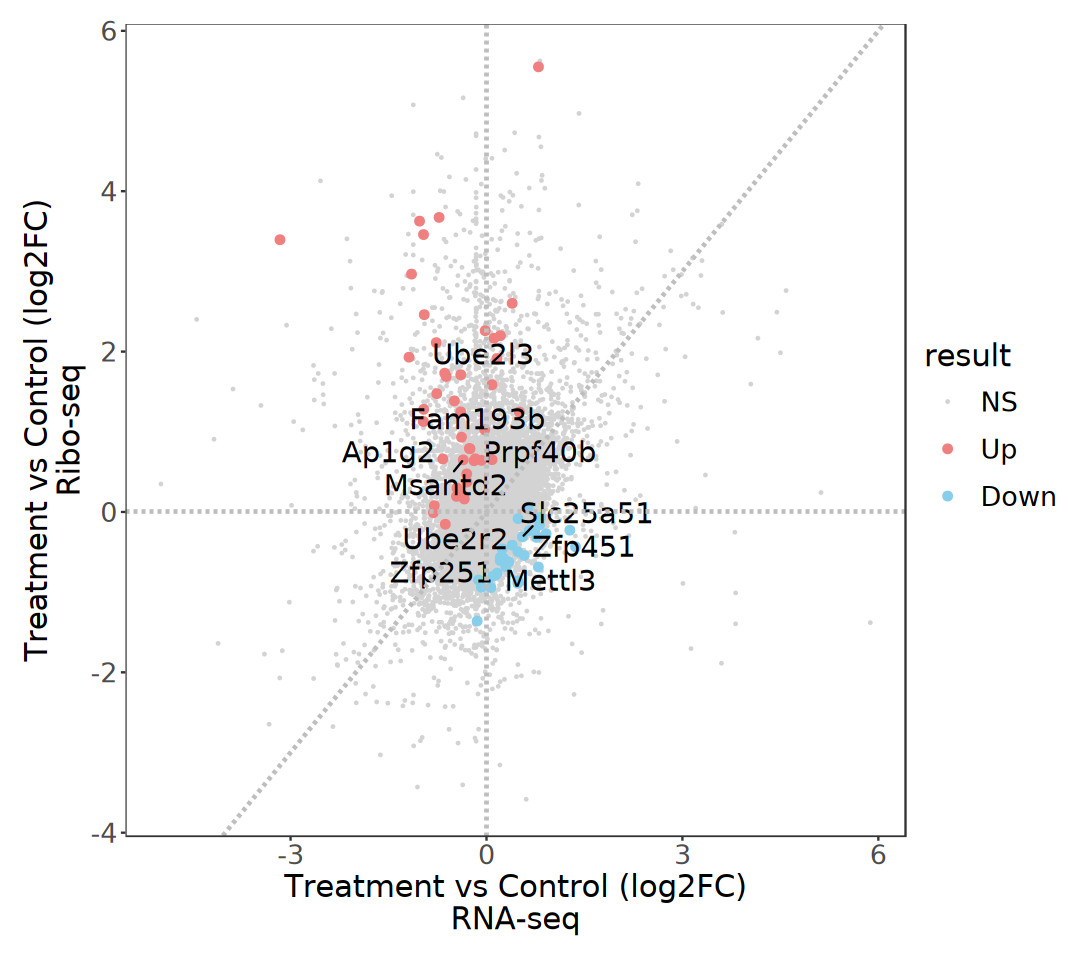

In [99]:
options(repr.plot.width = 9, repr.plot.height = 8)

# axisRange <- c(degs_result$log2FC_total, degs_result$log2FC_ribo) |> 
#     na.omit() %>% .[is.finite(.)] |> abs() |> max(na.rm = T) |> ceiling()

ggplot(degs_result, aes(x = log2FC_total, y = log2FC_ribo)) +
    geom_point(
        data = subset(degs_result, result == "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_point(
        data = subset(degs_result, result != "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_text_repel(
        aes(label = label),  na.rm = TRUE, size = 6, 
        color = "black", max.overlaps = Inf) +
    geom_hline(
        yintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    # xlim(-axisRange, axisRange) + 
    # ylim(-axisRange, axisRange) + 
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "LightGray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 0.3))+
    labs(
        x = "Treatment vs Control (log2FC)\n RNA-seq ", 
        y = "Treatment vs Control (log2FC)\n Ribo-seq ") + 
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [100]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [101]:
ar <- degs_result |> 
    dplyr::select(DTEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Group)

In [102]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Fraction = fraction_colors, 
    Replicate = replicate_colors, DTEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

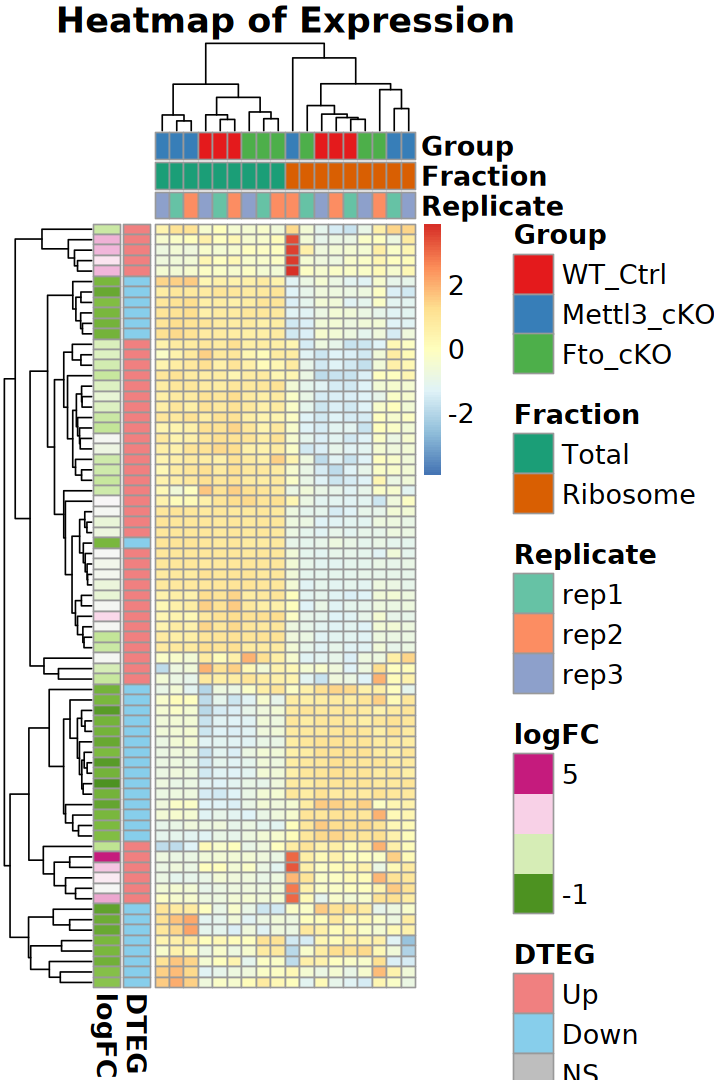

In [103]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [104]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [105]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [106]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [107]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Fraction, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Fraction = fraction_colors,
        Replicate = replicate_colors))

In [108]:
ar <- degs_result |> 
    dplyr::select(logFC, DTEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DTEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [109]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [110]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_fraction <- Legend(
    title = "Fraction", labels = levels(dds$Fraction))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DTEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_fraction, lg_replicate) |>
    packLegend(direction = "vertical")

In [111]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

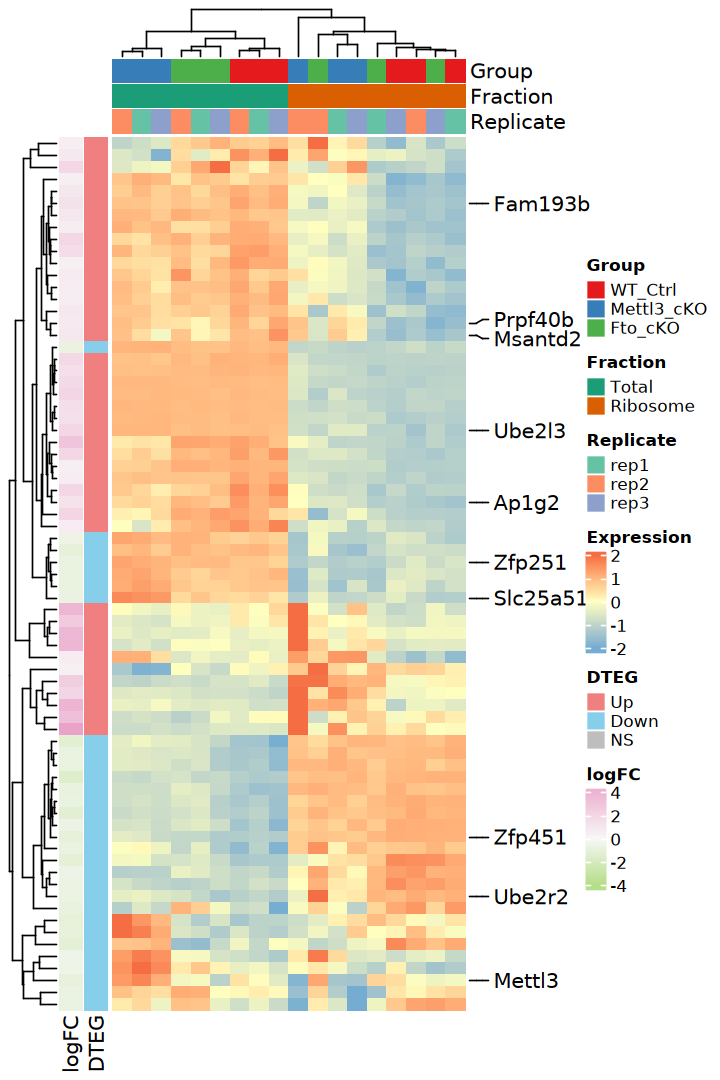

In [112]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

## 4). anota2seq

In [113]:
suppressPackageStartupMessages(library(anota2seq))
suppressPackageStartupMessages(library(tidySummarizedExperiment))

ℹ tidySummarizedExperiment says: The tidy printing is now handled externally.
If you want to visualize the data in a tidy way, do `library(tidyprint)`.
See `https://github.com/tidyomics/tidyprint` for more information.



In [114]:
ads <- anota2seqDataSetFromMatrix(
    dataP = eSet |> filter(
        Fraction == "Ribosome" & Group %in% c("WT_Ctrl", "Mettl3_cKO")) |> 
        assay("counts"),
    dataT = eSet |> filter(
        Fraction == "Total" & Group %in% c("WT_Ctrl", "Mettl3_cKO")) |> 
        assay("counts"),
    phenoVec = rep(c("WT_Ctrl", "Mettl3_cKO"), each = 3),
    dataType = "RNAseq", normalize = TRUE)

ads

Removing zero count genes from data ...


729  genes were removed due to having 0 counts in at least one sample.


Count data will be normalized and transformed according to the TMM-log2 method.


All input checkpoints passed.




Information on input data.
dataP and dataT contain data for 14054 mRNA and 6 samples. 

Your sample classes are:
 	 Mettl3_cKO WT_Ctrl 


No custom contrasts set, default will be used.
No differential expression analysis for translated mRNA has been detected.
No differential expression analysis for total mRNA has been detected.
No analysis of translation has been detected.
No analysis of buffering has been detected.
No selected data of differential expression analysis for translated mRNA has been detected.
No selected data of differential expression analysis for total mRNA has been detected.
No selected data of analysis of translation has been detected.
No selected data of analysis of buffering has been detected.

No output for mRNA abundance genes.

In [115]:
# ~ 3 min
ads <- anota2seqRun(ads)
ads

Running anota2seqPerformQc quality control


	Calculating omnibus interactions & effects and dfbetas




  |                                                                      |   0%

  |======================================================================| 100%





	Assessing dfbetas for model without interaction


	Performing dfbetas simulation




  |======================================================================| 100%





	Using RVM for omnibus interaction statistics


	The a and b parameters for the inverse gamma distribution are:
	a:1.09000531288801 b:20.5833442885061


	Using RVM for omnibus group statistics


	The a and b parameters for the inverse gamma distribution are:
	a:1.09167805042377 b:20.4397575190491


	Adjusting p-values for multiple testing



Running anota2seqResidOutlierTest




... (11 outputs left out)

           contrast 1
Mettl3_cKO         -1
WT_Ctrl             1


  |======================================================================| 100%





	Calculating RVM statistics


	Assessing contrast1


	The a and b parameters for the inverse gamma distribution are:
	a:0.86308922039657 b:68.1650232354668


End of analysis of translational buffering.


Start filtering for significant genes ... 


Your filtering parameters are:


minSlopeTranslation:  -1 


maxSlopeTranslation:  2 


minSlopeBuffering:  -2 


maxSlopeBuffering:  1 


maxPAdj:  0.15 


maxP:   


minEff:   


deltaPT:  0.263034405833794 


deltaTP:  0.263034405833794 


deltaP:   


deltaT:   





Starting filtering of: translated mRNA


	filtering contrast 1.


	Contrast 1 done.


Filtering for analysis translated mRNA done.


Starting filtering of: total mRNA


	filtering contrast 1.


	Contrast 1 done.


Filtering for analysis total mRNA done.


Starting filtering of: translation


	filtering contrast 1.


Warning message in anota2seqSelSigGenes(Anota2seqDataSet, selContrast = c(1:dim(contrasts)[2]), :
“No genes pass selected thresholds for analysis of translat

Information on input data.
dataP and dataT contain data for 14054 mRNA and 6 samples. 

Your sample classes are:
 	 Mettl3_cKO WT_Ctrl 

contrasts used in the analysis are:
			 WT_Ctrl 
	 Mettl3_cKO 		 -1 	
	 WT_Ctrl 		 1 	


Output for differential expression analysis of translated mRNA detected.

Output for differential expression analysis of total mRNA detected.

Output for analysis of translation detected.

Output for analysis of buffering detected.

Output for differential expression analysis of translated mRNA detected:
Selected output of translated mRNA contains:
	for contrast 1 
		Total: 2832 genes.
		Positive log2FC: 1457 genes.
		Negative log2FC: 1375 genes.

Output for differential expression analysis of total mRNA detected:
Selected output of total mRNA contains:
	for contrast 1 
		Total: 6379 genes.
		Positive log2FC: 3171 genes.
		Negative log2FC: 3208 genes.

Output for analysis of translation detected:
Selected output of translation contains:
	for contrast 1 
		Total: 0

Creating Fold-change plots.




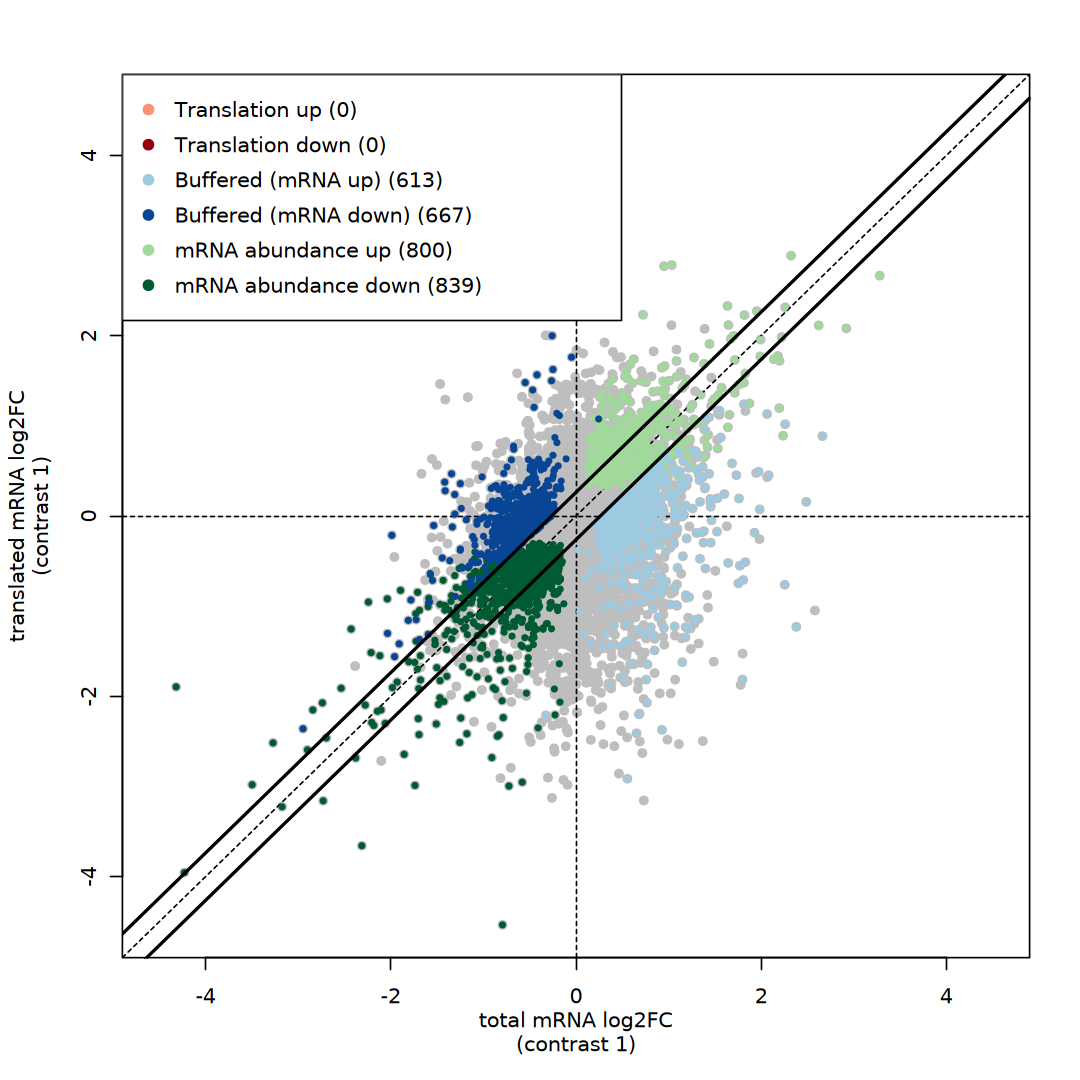

In [116]:
options(repr.plot.width = 9, repr.plot.height = 9)
anota2seqPlotFC(ads, selContrast = 1, plotToFile = FALSE)

In [117]:
ads_res <- anota2seqGetOutput(
    ads, analysis = "translation", output = "full", 
    getRVM = TRUE, selContrast = 1)

head(ads_res)

,apvSlope,apvSlopeP,apvEff,apvRvmMSerror,apvRvmF,residRvmDf,apvRvmP,apvRvmPAdj
ENSMUSG00000051951.5,-0.1989201,0.3036770,-0.05515446,0.03400052,0.08946964,4.807014,0.777350290,0.9193045
ENSMUSG00000025902.13,1.1005651,0.4158828,-1.15025289,0.07596765,17.41638213,4.807014,0.009481479,0.4331798
ENSMUSG00000033845.13,1.4576266,0.4760086,0.16488287,1.73017512,0.01571307,4.807014,0.905317753,0.9672102
ENSMUSG00000025903.14,-0.7288927,0.2599922,0.31401593,0.07662772,1.28681897,4.807014,0.310015142,0.6674254
ENSMUSG00000033813.15,-0.6488229,0.3761901,1.21076702,0.12877248,11.38408469,4.807014,0.021042401,0.4360672
ENSMUSG00000002459.17,1.4433700,0.3140602,0.32656041,0.03213204,3.31885847,4.807014,0.130457869,0.5229993


## 5). deltaTE

In [118]:
forwarded <- Reduce(
    intersect, list(
        rownames(res_lfc[which(res_lfc$padj >= 0.05),]), 
        rownames(res_total[which(res_total$padj < 0.05),]), 
        rownames(res_ribo[which(res_ribo$padj < 0.05),])))

length(forwarded)

[1] 361

In [119]:
exclusive <- Reduce(
    intersect, list(
        rownames(res_lfc[which(res_lfc$padj < 0.05),]), 
        rownames(res_total[which(res_total$padj < 0.05),]), 
        rownames(res_ribo[which(res_ribo$padj >= 0.05),])))

length(exclusive)

[1] 19

In [120]:
both <- Reduce(intersect, list(
        rownames(res_lfc[which(res_lfc$padj < 0.05),]), 
        rownames(res_total[which(res_total$padj < 0.05),]), 
        rownames(res_ribo[which(res_ribo$padj < 0.05),])))

length(both)

intensified <- both[which(
    res_lfc[both, ]$log2FoldChange * res_total[both, ]$log2FoldChange > 0)]

length(intensified)

[1] 7

[1] 1

In [121]:
buffered_tmp1 <- both[which(
    res_lfc[both, ]$log2FoldChange * res_total[both, ]$log2FoldChange < 0)]
buffered_tmp2 <- Reduce(
    intersect, list(
        rownames(res_lfc[which(res_lfc$padj < 0.05),]), 
        rownames(res_total[which(res_total$padj >= 0.05),]), 
        rownames(res_ribo[which(res_ribo$padj >= 0.05),])))

buffered <- unique(c(buffered_tmp1, buffered_tmp2))

length(buffered)

[1] 8

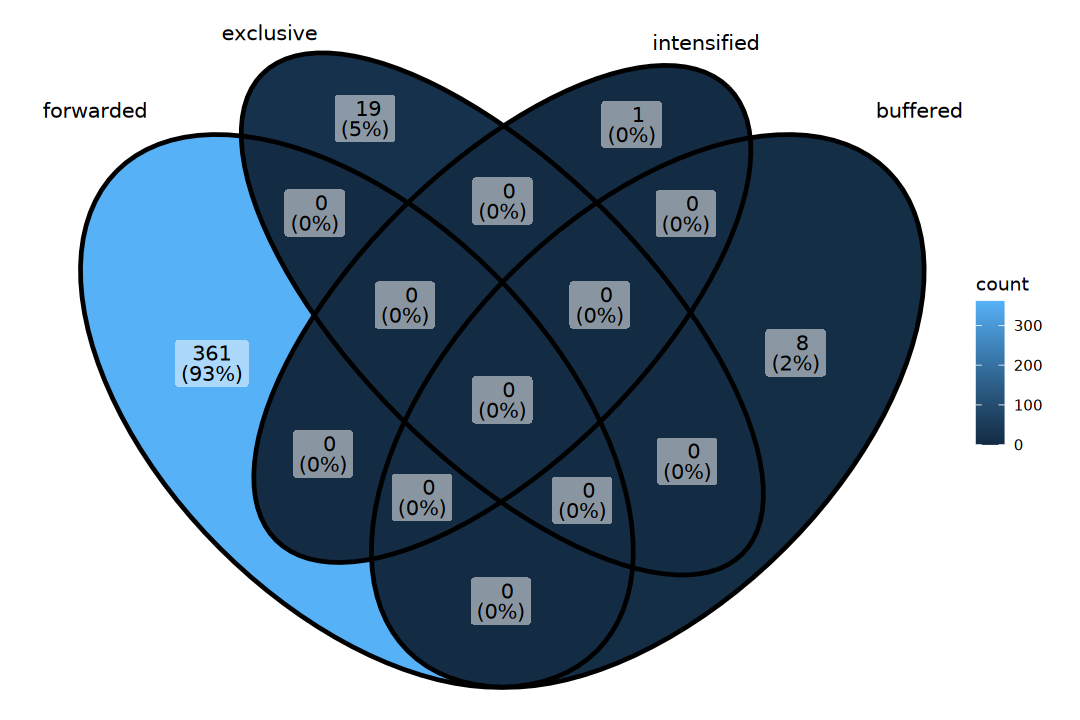

In [122]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggVennDiagram(
    list(
        forwarded = forwarded, 
        exclusive = exclusive, 
        intensified = intensified, 
        buffered = buffered))

In [123]:
degs_result <- degs_result |> 
    mutate(deltaTE = case_when(
        rownames(degs_result) %in% forwarded   ~ "forwarded",
        rownames(degs_result) %in% exclusive   ~ "exclusive",
        rownames(degs_result) %in% intensified ~ "intensified",
        rownames(degs_result) %in% buffered    ~ "buffered",
        TRUE                                   ~ "NS"))

table(degs_result$deltaTE)


   buffered   exclusive   forwarded intensified          NS 
          8          19         361           1       14394 

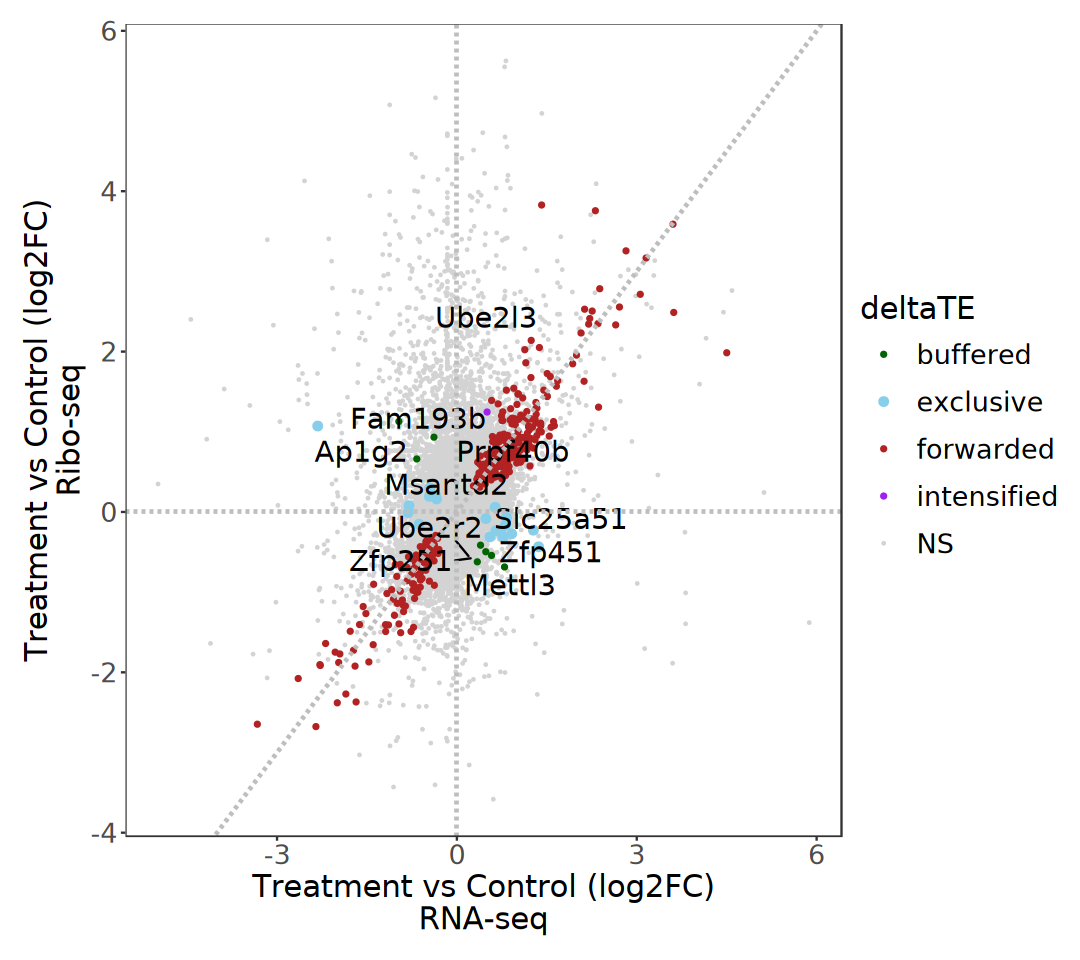

In [124]:
options(repr.plot.width = 9, repr.plot.height = 8)

# axisRange <- c(degs_result$log2FC_total, degs_result$log2FC_ribo) |> 
#     na.omit() %>% .[is.finite(.)] |> abs() |> max(na.rm = T) |> ceiling()

ggplot(degs_result, aes(x = log2FC_total, y = log2FC_ribo)) +
    geom_point(
        data = subset(degs_result, deltaTE == "NS"), 
        aes(color = deltaTE, size = deltaTE), na.rm = TRUE) + 
    geom_point(
        data = subset(degs_result, deltaTE != "NS"), 
        aes(color = deltaTE, size = deltaTE), na.rm = TRUE) + 
    geom_text_repel(
        aes(label = label),  na.rm = TRUE, size = 6, 
        color = "black", max.overlaps = Inf) +
    geom_hline(
        yintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    # xlim(-axisRange, axisRange) + 
    # ylim(-axisRange, axisRange) + 
    scale_color_manual(
        values = c(forwarded = "FireBrick", exclusive = "SkyBlue",  
        intensified = "Purple", buffered = "DarkGreen", NS = "LightGray")) +
    scale_size_manual(
        values = c(forwarded = 1, exclusive = 2,  
        intensified = 1, buffered = 1, NS = 0.3))+
    labs(
        x = "Treatment vs Control (log2FC)\n RNA-seq ", 
        y = "Treatment vs Control (log2FC)\n Ribo-seq ") + 
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)